# Mobile-Wallet Fraud Detection & Cost Optimization (PaySim)

Audited and corrected version of the project notebook.

**How to run**
1. `pip install -r requirements.txt` (tested with Python 3.12; the original model was trained with 3.13).
2. Download PaySim from Kaggle (`ealaxi/paysim1`) and save the CSV as `data/PS_20174392719_1491204439457_log.csv`
   (or set the environment variable `PAYSIM_CSV` to its location).
3. Run all cells from the project root (this notebook sits next to `paysim_features.py`).
   Expect roughly 15-30 minutes on a laptop (model comparison, tuning and the final refits dominate).
4. The last section writes `paysim_fraud_bundle.pkl`, `sample_transactions_demo.csv` and
   `sample_transactions_realistic.csv` next to `app.py`.

**Evaluation protocol - which data may be used for what**

| Data | Used for | Never used for |
|---|---|---|
| fit split (60 %) | training, undersampled CV / tuning, final refit | - |
| validation split (20 %) | model comparison, calibration check, threshold and policy choice, ablation | training |
| test split (20 %) | one final evaluation and error analysis (interpretation only) | any decision |

Markdown cells avoid quoting result numbers on purpose: every figure is produced by the code cell next to it.

## 1 · Problem framing
* **Who has the problem?** Mobile-money platforms and digital wallets (for example Vodafone Cash or InstaPay in Egypt)
  that process millions of peer-to-peer transfers and cash-outs.
* **Decision supported:** approve a TRANSFER / CASH_OUT, send it to manual review (step-up authentication), or block it.
* **Target:** `isFraud` (1 = fraud).
* **Primary metrics**
  1. **PR-AUC (average precision):** fraud is extremely rare, so accuracy is meaningless (a model that never flags
     anything is almost 100 % "accurate"); PR-AUC evaluates the ranking of the minority class directly.
  2. **Expected financial cost:** a missed fraud costs its full `amount` (a *proxy* for the real loss), a false alarm
     costs `FP_COST` (an *assumption*, default 50). Both are modelling assumptions, not measured operational costs.
     The decision threshold is chosen on the **validation** set to minimise this total cost.
* **Scope caveat:** the full model uses balances recorded *after* the transaction. It screens executed transactions;
  it is **not** a pre-authorisation model (see the ablation study).

In [1]:
import gc
import json
import os
import platform
import subprocess
import sys
import time
import warnings
from pathlib import Path

import joblib
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix, log_loss,precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from paysim_features import (
    ELIGIBLE_TYPES, REQUIRED_COLUMNS, CalibratedPipeline, OutlierCapper, PaySimFeatureEngineer, apply_logit_platt,
    build_preprocessing_pipeline, cost_curve, cost_of, decision_tier, fit_logit_platt,
    model_feature_names, near_optimal_range, recost, select_threshold,
)

# ---- configuration --------------------------------------------------------------------------
RANDOM_STATE = 42
FP_COST = 50.0                  # ASSUMPTION: cost of flagging one legitimate transaction
BLOCK_THRESHOLD = 0.50          # POLICY parameter of the auto-block tier - documented, NOT optimised
UNDERSAMPLE_LEGIT_N = 150_000   # legitimate rows kept in the undersampled tuning set
N_ITER = 12                     # random-search candidates
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
CALIBRATION_MIN_GAIN = 0.05     # adopt calibration if out-of-fold log-loss improves by at least 5 %
CAP_OUTLIERS = False            # winsorize heavy-tailed features inside the pipeline? (evidence: sections 4b and 16)
# subsample_freq=1 makes `subsample` effective (LightGBM ignores it when subsample_freq=0);
# deterministic/force_row_wise make results reproducible across thread counts.
LGBM_PARAMS = dict(random_state=RANDOM_STATE, verbose=-1, subsample_freq=1,
                   deterministic=True, force_row_wise=True)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "paysim_features.py").exists():
    raise FileNotFoundError("Run this notebook from the project root (the folder containing paysim_features.py).")
DATA_PATH = Path(os.environ.get("PAYSIM_CSV", PROJECT_ROOT / "data" / "PS_20174392719_1491204439457_log.csv"))
BUNDLE_PATH = PROJECT_ROOT / "paysim_fraud_bundle.pkl"


def make_preprocessing(**kwargs):
    # preprocessing pipeline with the notebook-wide outlier-capping setting
    return build_preprocessing_pipeline(cap_outliers=CAP_OUTLIERS, **kwargs)


sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | lightgbm {lightgbm.__version__} "
      f"| pandas {pd.__version__} | numpy {np.__version__}")

Matplotlib is building the font cache; this may take a moment.


Python 3.12.10 | scikit-learn 1.7.1 | lightgbm 4.7.0 | pandas 2.3.1 | numpy 2.2.6


## 2 · Data understanding
* **Source:** PaySim mobile-money simulation (Kaggle: `ealaxi/paysim1`). It imitates the logs of a mobile-money service,
  but every record is **synthetic**.
* **Columns:** `step` (1 step = 1 hour; 744 steps is about 31 days although the Kaggle page says 30), `type`
  (`CASH_IN`, `CASH_OUT`, `DEBIT`, `PAYMENT`, `TRANSFER`), `amount`, `nameOrig` / `nameDest` (account ids, never used as
  features), `oldbalanceOrg` / `newbalanceOrig`, `oldbalanceDest` / `newbalanceDest` (balances before / after),
  `isFraud` (target) and `isFlaggedFraud` (legacy rule: TRANSFER above 200,000).
* **Why only TRANSFER and CASH_OUT?** This is **checked in code** below, not assumed: the scope cell raises an error if
  fraud appears in any other type.
* The full dataset is used here only for **descriptive facts and the scope decision**. Everything that motivates a feature
  is recomputed on the training split in section 4.
* Numeric columns are loaded as **float64**. float32 would round large amounts and balances and corrupt exact
  comparisons such as `amount == oldbalanceOrg` and differences such as `old - amount - new`.

Dataset shape: (6362620, 11)

--- Missing values per column ---
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0

Overall fraud rate: 0.1291% (8,213 frauds)

--- Transaction type vs. isFraud ---


isFraud,0,1,All,Fraud_Rate (%)
type,,,,
CASH_IN,1399284,0,1399284,0.0000
CASH_OUT,2233384,4116,2237500,0.1840
DEBIT,41432,0,41432,0.0000
PAYMENT,2151495,0,2151495,0.0000
TRANSFER,528812,4097,532909,0.7688
All,6354407,8213,6362620,0.1291


--- Legacy rule (isFlaggedFraud) vs. actual fraud ---


Flagged by rule,0,1
Actual fraud,,
0,6354407,0
1,8197,16


Fraud occurs only in: ['CASH_OUT', 'TRANSFER']  (eligible scope: ['TRANSFER', 'CASH_OUT'])

Scope summary: {'n_rows_total': 6362620, 'n_rows_scope': 2770409, 'n_rows_other_types': 3592211, 'fraud_in_other_types': 0, 'fraud_total': 8213, 'fraud_in_scope': 8213, 'fraud_rate_overall': 0.001290820448180152, 'fraud_rate_scope': 0.002964544224336551}


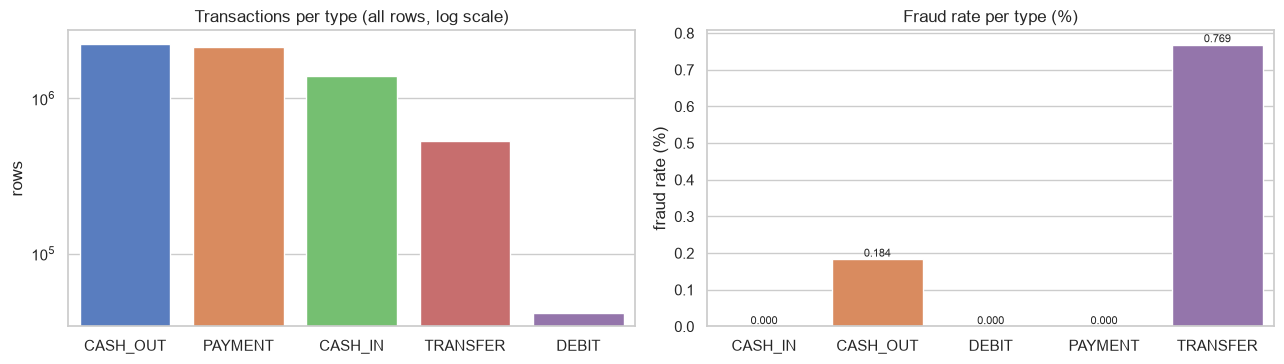

In [2]:
DTYPES = {
    "step": "int16", "type": "category", "amount": "float64", "nameOrig": "object",
    "oldbalanceOrg": "float64", "newbalanceOrig": "float64", "nameDest": "object",
    "oldbalanceDest": "float64", "newbalanceDest": "float64", "isFraud": "int8", "isFlaggedFraud": "int8",
}
if not DATA_PATH.exists():
    raise FileNotFoundError(f"PaySim CSV not found at {DATA_PATH}. Download it from Kaggle (ealaxi/paysim1) "
                            "and place it in the data/ folder, or set the PAYSIM_CSV environment variable.")
df = pd.read_csv(DATA_PATH, dtype=DTYPES)
assert set(DTYPES) <= set(df.columns), f"missing columns: {set(DTYPES) - set(df.columns)}"

print(f"Dataset shape: {df.shape}")
print("\n--- Missing values per column ---")
print(df.isnull().sum().to_string())

overall_fraud_rate = float(df["isFraud"].mean())
print(f"\nOverall fraud rate: {overall_fraud_rate:.4%} ({int(df['isFraud'].sum()):,} frauds)")

print("\n--- Transaction type vs. isFraud ---")
type_fraud = pd.crosstab(df["type"], df["isFraud"], margins=True)
type_fraud["Fraud_Rate (%)"] = (type_fraud[1] / type_fraud["All"] * 100).round(4)
display(type_fraud)

print("--- Legacy rule (isFlaggedFraud) vs. actual fraud ---")
display(pd.crosstab(df["isFraud"], df["isFlaggedFraud"], rownames=["Actual fraud"], colnames=["Flagged by rule"]))

# ---- scope verification (computed, not assumed) ---------------------------------------------
fraud_types = sorted(df.loc[df["isFraud"] == 1, "type"].astype(str).unique())
if not set(fraud_types) <= set(ELIGIBLE_TYPES):
    raise ValueError(f"Fraud occurs in {fraud_types}, outside ELIGIBLE_TYPES={ELIGIBLE_TYPES}. Update the scope.")
print(f"Fraud occurs only in: {fraud_types}  (eligible scope: {list(ELIGIBLE_TYPES)})")

in_scope = df["type"].isin(ELIGIBLE_TYPES)
scope_df = df.loc[in_scope].copy()
scope_df["type"] = scope_df["type"].astype(str)
scope_stats = {
    "n_rows_total": int(len(df)), "n_rows_scope": int(len(scope_df)),
    "n_rows_other_types": int((~in_scope).sum()), "fraud_in_other_types": int(df.loc[~in_scope, "isFraud"].sum()),
    "fraud_total": int(df["isFraud"].sum()), "fraud_in_scope": int(scope_df["isFraud"].sum()),
    "fraud_rate_overall": overall_fraud_rate, "fraud_rate_scope": float(scope_df["isFraud"].mean()),
}
print("\nScope summary:", scope_stats)

type_counts = df["type"].value_counts()
type_rates = type_fraud.drop(index="All")["Fraud_Rate (%)"].astype(float)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.barplot(x=type_counts.index.astype(str), y=type_counts.values, hue=type_counts.index.astype(str), legend=False, ax=axes[0])
axes[0].set(yscale="log", title="Transactions per type (all rows, log scale)", ylabel="rows", xlabel="")
sns.barplot(x=type_rates.index.astype(str), y=type_rates.values, hue=type_rates.index.astype(str), legend=False, ax=axes[1])
axes[1].set(title="Fraud rate per type (%)", ylabel="fraud rate (%)", xlabel="")
for patch, value in zip(axes[1].patches, type_rates.values):
    axes[1].annotate(f"{value:.3f}", (patch.get_x() + patch.get_width() / 2, patch.get_height()), ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

del df
_ = gc.collect()

## 3 · Train / validation / test split (before anything else)
* The split happens **before** EDA-for-features, undersampling, imputation or scaling.
* Stratified random 60 / 20 / 20 split of the TRANSFER / CASH_OUT scope.
* A **random** split of this synthetic dataset does not demonstrate generalisation to future periods; two diagnostics
  at the end (account overlap and a time-ordered check) look at how serious that limitation is.

,rows,frauds,fraud_rate_%
fit (60%),1662245,4927,0.2964
validation (20%),554082,1643,0.2965
test (20%),554082,1643,0.2965


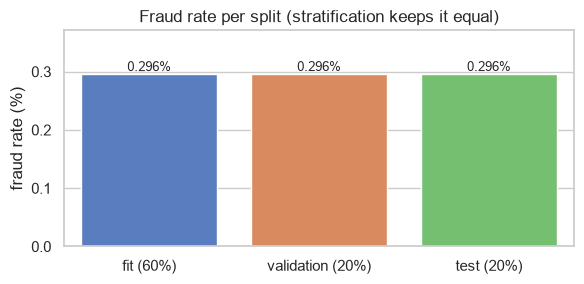

In [3]:
X = scope_df.drop(columns=["isFraud"])
y = scope_df["isFraud"]

# test = untouched until the final evaluation | validation = natural distribution, used for decisions | fit = training
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_fit, X_val, y_fit, y_val = train_test_split(X_trainval, y_trainval, test_size=0.25, stratify=y_trainval,random_state=RANDOM_STATE)

assert not (set(X_fit.index) & set(X_val.index)) and not (set(X_fit.index) & set(X_test.index)) \
    and not (set(X_val.index) & set(X_test.index)), "splits overlap"
split_summary = pd.DataFrame({
    "rows": [len(X_fit), len(X_val), len(X_test)],
    "frauds": [int(y_fit.sum()), int(y_val.sum()), int(y_test.sum())],
    "fraud_rate_%": [round(y_fit.mean() * 100, 4), round(y_val.mean() * 100, 4), round(y_test.mean() * 100, 4)],
}, index=["fit (60%)", "validation (20%)", "test (20%)"])
display(split_summary)

fig, ax = plt.subplots(figsize=(6, 3))
sns.barplot(x=split_summary.index, y=split_summary["fraud_rate_%"], hue=split_summary.index, legend=False, ax=ax)
for patch, value in zip(ax.patches, split_summary["fraud_rate_%"]):
    ax.annotate(f"{value:.3f}%", (patch.get_x() + patch.get_width() / 2, patch.get_height()), ha="center", va="bottom", fontsize=9)
ax.set(title="Fraud rate per split (stratification keeps it equal)", ylabel="fraud rate (%)", xlabel="")
ax.set_ylim(0, split_summary["fraud_rate_%"].max() * 1.25)
plt.tight_layout()
plt.show()

## 4 · EDA on the training split only
Statistics that motivate features (balance behaviour, hour pattern) are computed on the **fit split** so that no
information from validation or test rows influences feature design.

=== Balance behaviour of fraud vs. legitimate rows (fit split) ===


,Count,Mean_Amount,Median_Amount,Pct_Account_Emptied,Pct_NewBalanceOrig_Zero,Pct_Dest_Zero_Before_After
isFraud,,,,,,
0,1657318,3.141706e+05,171029.465,0.000,90.10,0.061
1,4927,1.460658e+06,434006.520,97.585,98.13,50.112


=== Five highest fraud-rate hours (hour = step % 24) ===


,Total_Tx,Fraud_Tx,Fraud_Rate_Pct
hour_of_day,,,
5,397,224,56.42
4,301,166,55.15
3,456,192,42.11
6,520,217,41.73
2,1151,215,18.68


Average frauds per hour: 205.3 | min 166 | max 224


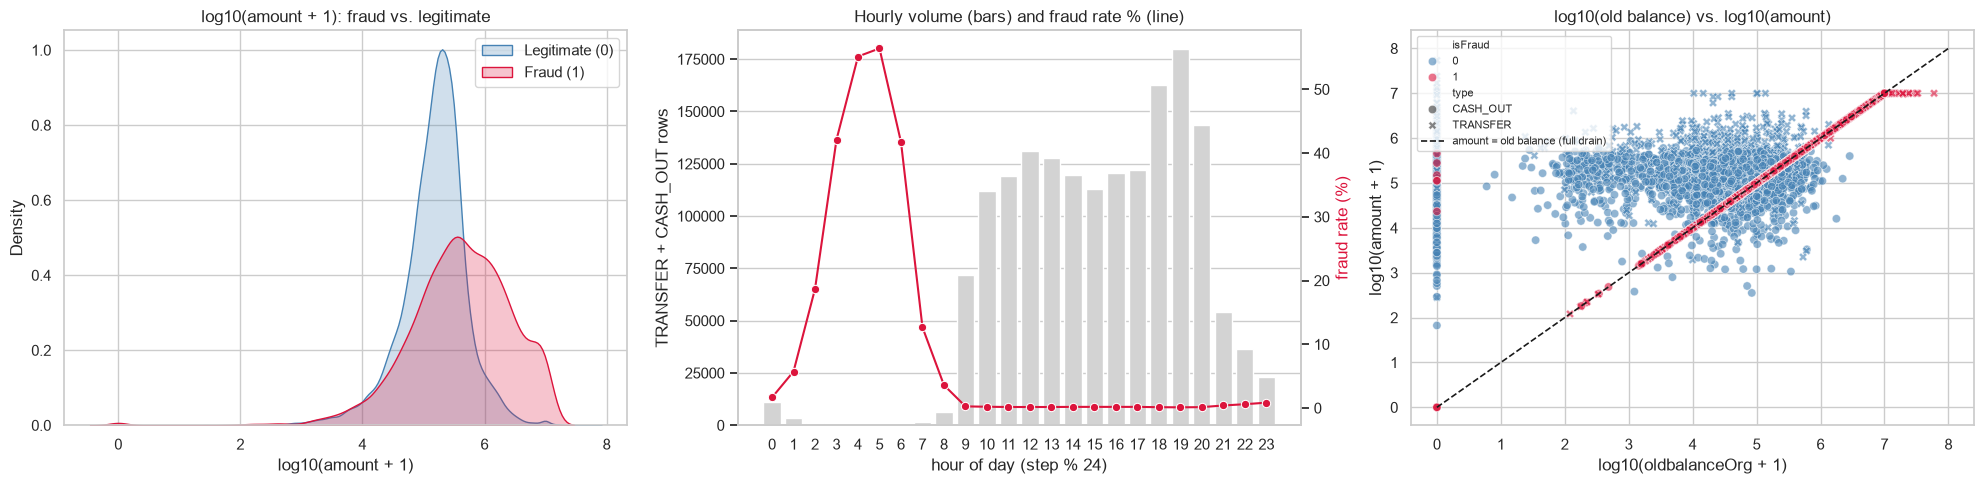

In [4]:
eda = X_fit.assign(isFraud=y_fit.to_numpy())
eda["hour_of_day"] = eda["step"] % 24
eda["is_account_emptied"] = (eda["amount"] == eda["oldbalanceOrg"]) & (eda["oldbalanceOrg"] > 0)
eda["dest_zero_before_after"] = (eda["oldbalanceDest"] == 0) & (eda["newbalanceDest"] == 0) & (eda["amount"] > 0)

print("=== Balance behaviour of fraud vs. legitimate rows (fit split) ===")
behaviour = eda.groupby("isFraud").agg(
    Count=("amount", "count"), Mean_Amount=("amount", "mean"), Median_Amount=("amount", "median"),
    Pct_Account_Emptied=("is_account_emptied", lambda s: round(s.mean() * 100, 3)),
    Pct_NewBalanceOrig_Zero=("newbalanceOrig", lambda s: round((s == 0).mean() * 100, 2)),
    Pct_Dest_Zero_Before_After=("dest_zero_before_after", lambda s: round(s.mean() * 100, 3)),
)
display(behaviour)

hourly = eda.groupby("hour_of_day").agg(Total_Tx=("isFraud", "count"), Fraud_Tx=("isFraud", "sum"))
hourly["Fraud_Rate_Pct"] = (hourly["Fraud_Tx"] / hourly["Total_Tx"] * 100).round(2)
print("=== Five highest fraud-rate hours (hour = step % 24) ===")
display(hourly.sort_values("Fraud_Rate_Pct", ascending=False).head(5))
print(f"Average frauds per hour: {hourly['Fraud_Tx'].mean():.1f} | min {hourly['Fraud_Tx'].min()} | max {hourly['Fraud_Tx'].max()}")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
legit_sample = eda[eda["isFraud"] == 0].sample(min(50_000, int((eda["isFraud"] == 0).sum())), random_state=RANDOM_STATE)
sns.kdeplot(x=np.log10(legit_sample["amount"] + 1), label="Legitimate (0)", fill=True, ax=axes[0], color="steelblue")
sns.kdeplot(x=np.log10(eda.loc[eda["isFraud"] == 1, "amount"] + 1), label="Fraud (1)", fill=True, ax=axes[0], color="crimson")
axes[0].set(title="log10(amount + 1): fraud vs. legitimate", xlabel="log10(amount + 1)")
axes[0].legend()

twin = axes[1].twinx()
sns.barplot(x=hourly.index, y=hourly["Total_Tx"], ax=axes[1], color="lightgray")
sns.lineplot(x=range(len(hourly)), y=hourly["Fraud_Rate_Pct"].to_numpy(), ax=twin, color="crimson", marker="o")
axes[1].set(title="Hourly volume (bars) and fraud rate % (line)", xlabel="hour of day (step % 24)",
            ylabel="TRANSFER + CASH_OUT rows")
twin.set_ylabel("fraud rate (%)", color="crimson")
twin.grid(False)

n_fraud_plot = min(2_000, int((eda["isFraud"] == 1).sum()))
n_legit_plot = min(5_000, int((eda["isFraud"] == 0).sum()))
plot_sample = pd.concat([eda[eda["isFraud"] == 0].sample(n_legit_plot, random_state=RANDOM_STATE),
                         eda[eda["isFraud"] == 1].sample(n_fraud_plot, random_state=RANDOM_STATE)])
sns.scatterplot(data=plot_sample, x=np.log10(plot_sample["oldbalanceOrg"] + 1), y=np.log10(plot_sample["amount"] + 1),
                hue="isFraud", style="type", palette={0: "steelblue", 1: "crimson"}, alpha=0.6, ax=axes[2])
axes[2].plot([0, 8], [0, 8], "k--", linewidth=1.2, label="amount = old balance (full drain)")
axes[2].set(title="log10(old balance) vs. log10(amount)", xlabel="log10(oldbalanceOrg + 1)", ylabel="log10(amount + 1)")
axes[2].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

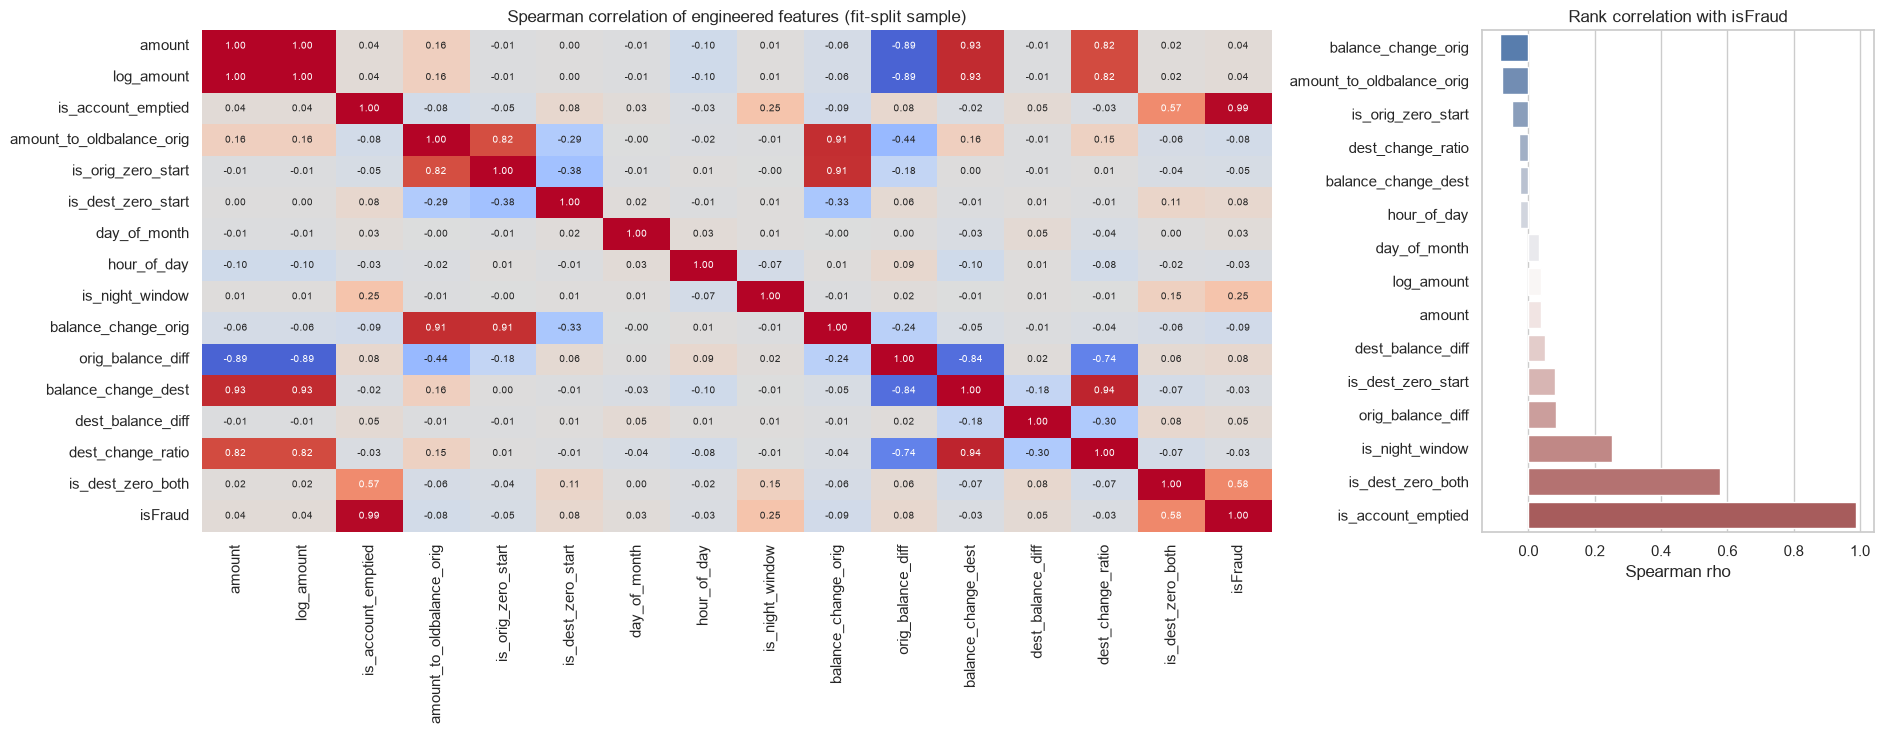

In [5]:
# Spearman rank correlation of the engineered features (robust to heavy tails), fit-split sample
fe_sample = PaySimFeatureEngineer().transform(X_fit.sample(min(200_000, len(X_fit)), random_state=RANDOM_STATE))
corr_data = fe_sample.drop(columns=["type"]).assign(isFraud=y_fit.loc[fe_sample.index].to_numpy())
corr = corr_data.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(19, 7.5), gridspec_kw={"width_ratios": [3, 1.1]})
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, cbar=False, ax=axes[0])
axes[0].set_title("Spearman correlation of engineered features (fit-split sample)")
target_corr = corr["isFraud"].drop("isFraud").sort_values()
sns.barplot(x=target_corr.values, y=target_corr.index, hue=target_corr.index, legend=False, palette="vlag", ax=axes[1])
axes[1].set(title="Rank correlation with isFraud", xlabel="Spearman rho", ylabel="")
plt.tight_layout()
plt.show()

### How to read the EDA (and what it does *not* show)
* **Account-draining pattern:** read `Pct_Account_Emptied`. Fraud rows overwhelmingly send the *entire* sender balance
  (`amount == oldbalanceOrg`), legitimate rows almost never do. `is_account_emptied` is therefore a feature, and it uses
  only information available **before** execution.
* **Raw `newbalanceOrig == 0` is common among legitimate rows too**, so post-transaction balances need care: they are
  both powerful and unavailable before the transaction is executed.
* **Recipient balance discrepancy:** a large share of fraud rows leave the recipient balance at zero before *and* after
  (`Pct_Dest_Zero_Before_After`), which almost never happens for legitimate rows. This uses `newbalanceDest`, i.e. a
  **post-transaction** quantity.
* **Hour-of-day (simulator artefact):** compare the *count* of frauds per hour with the fraud *rate*. If the counts are
  roughly flat while the rate peaks at night, the peak comes from low legitimate volume at night, not from more attacks.
  Real fraud timing is different, so hour features must not be read as real customer behaviour (ablation C tests how
  much the model depends on them).
* **Large amounts:** fraud amounts are larger on average, which is why a missed fraud is expensive and why the evaluation
  is cost-based.
* **Legacy rule:** `isFlaggedFraud` catches almost none of the fraud; it is only a weak baseline.
* The `is_night_window` definition (hours 2-6) was chosen by looking at hourly rates; here they are recomputed on the
  fit split only. (The original notebook looked at the whole dataset; this is a small, disclosed source of optimism that
  this version removes for the tables above, but the window itself is unchanged.)

## 4b · Outlier analysis and cleaning (fit split only)
**Method.** Boxplot rule (Tukey): a value is an outlier if it lies more than 1.5 x IQR beyond the quartiles. Quartiles and
fences come from the **fit split only**. Money amounts are extremely right-skewed and zero-inflated (many empty accounts), so
the rule is applied on a **log scale to the non-zero values**; a zero is a legitimate state (an empty account) and is never
an outlier.

**Why extreme values are not simply deleted.** In fraud detection extreme values are often the signal, not noise: fraud rows
are larger on average, so dropping "outlier" rows would delete fraud, change the fraud rate and make validation and test
unrepresentative (production sees every transaction, including the extreme ones). The table below measures this: compare the
fraud rate *inside* the outliers with the rate *outside*.

**What "cleaning" means here**
1. *Invalid data* (negative or non-finite amounts, exact duplicate rows) is removed from the **fit split only**; validation and
   test keep every row, as production data would.
2. *Extreme but valid values* are **winsorized** (capped at the boxplot whisker) by `OutlierCapper`, fitted on training data
   only. No rows are removed. The capper can run inside the pipeline (`CAP_OUTLIERS = True`); ablation D in section 16
   measures on validation data whether it helps, and it should be switched on only if it does. Tree models such as LightGBM
   split on thresholds and are already insensitive to outliers, so little benefit is expected; Logistic Regression is the model
   that suffers from heavy tails.

In [6]:
money_cols = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]


def invalid_row_masks(X_part, y_part):
    values = X_part[money_cols].to_numpy(dtype=float)
    bad_numbers = (~np.isfinite(values)).any(axis=1) | (values < 0).any(axis=1)
    duplicated = pd.concat([X_part, y_part.rename("isFraud")], axis=1).duplicated().to_numpy()
    return bad_numbers, duplicated


rows = []
for split_name, X_part, y_part in [("fit", X_fit, y_fit), ("validation", X_val, y_val), ("test", X_test, y_test)]:
    bad_numbers, duplicated = invalid_row_masks(X_part, y_part)
    rows.append({"split": split_name, "rows": len(X_part), "negative / non-finite money values": int(bad_numbers.sum()),
                 "exact duplicate rows": int(duplicated.sum())})
print("Data-validity check (genuine data errors, as opposed to extreme-but-valid values):")
display(pd.DataFrame(rows))

bad_numbers, duplicated = invalid_row_masks(X_fit, y_fit)
drop_mask = bad_numbers | duplicated
if drop_mask.any():
    X_fit, y_fit = X_fit.loc[~drop_mask], y_fit.loc[~drop_mask]
    print(f"Removed {int(drop_mask.sum())} invalid row(s) from the FIT split only.")
else:
    print("No invalid rows in the fit split: nothing to remove. (Validation and test are never filtered.)")

Data-validity check (genuine data errors, as opposed to extreme-but-valid values):


,split,rows,negative / non-finite money values,exact duplicate rows
0,fit,1662245,0,0
1,validation,554082,0,0
2,test,554082,0,0


No invalid rows in the fit split: nothing to remove. (Validation and test are never filtered.)


Share of exact zeros per column (a legitimate state for balances; never an outlier):


,zeros among legitimate (%),zeros among fraud (%)
amount,0.00,0.24
oldbalanceOrg,47.37,0.61
newbalanceOrig,90.10,98.13
oldbalanceDest,13.91,65.92
newbalanceDest,0.45,50.29


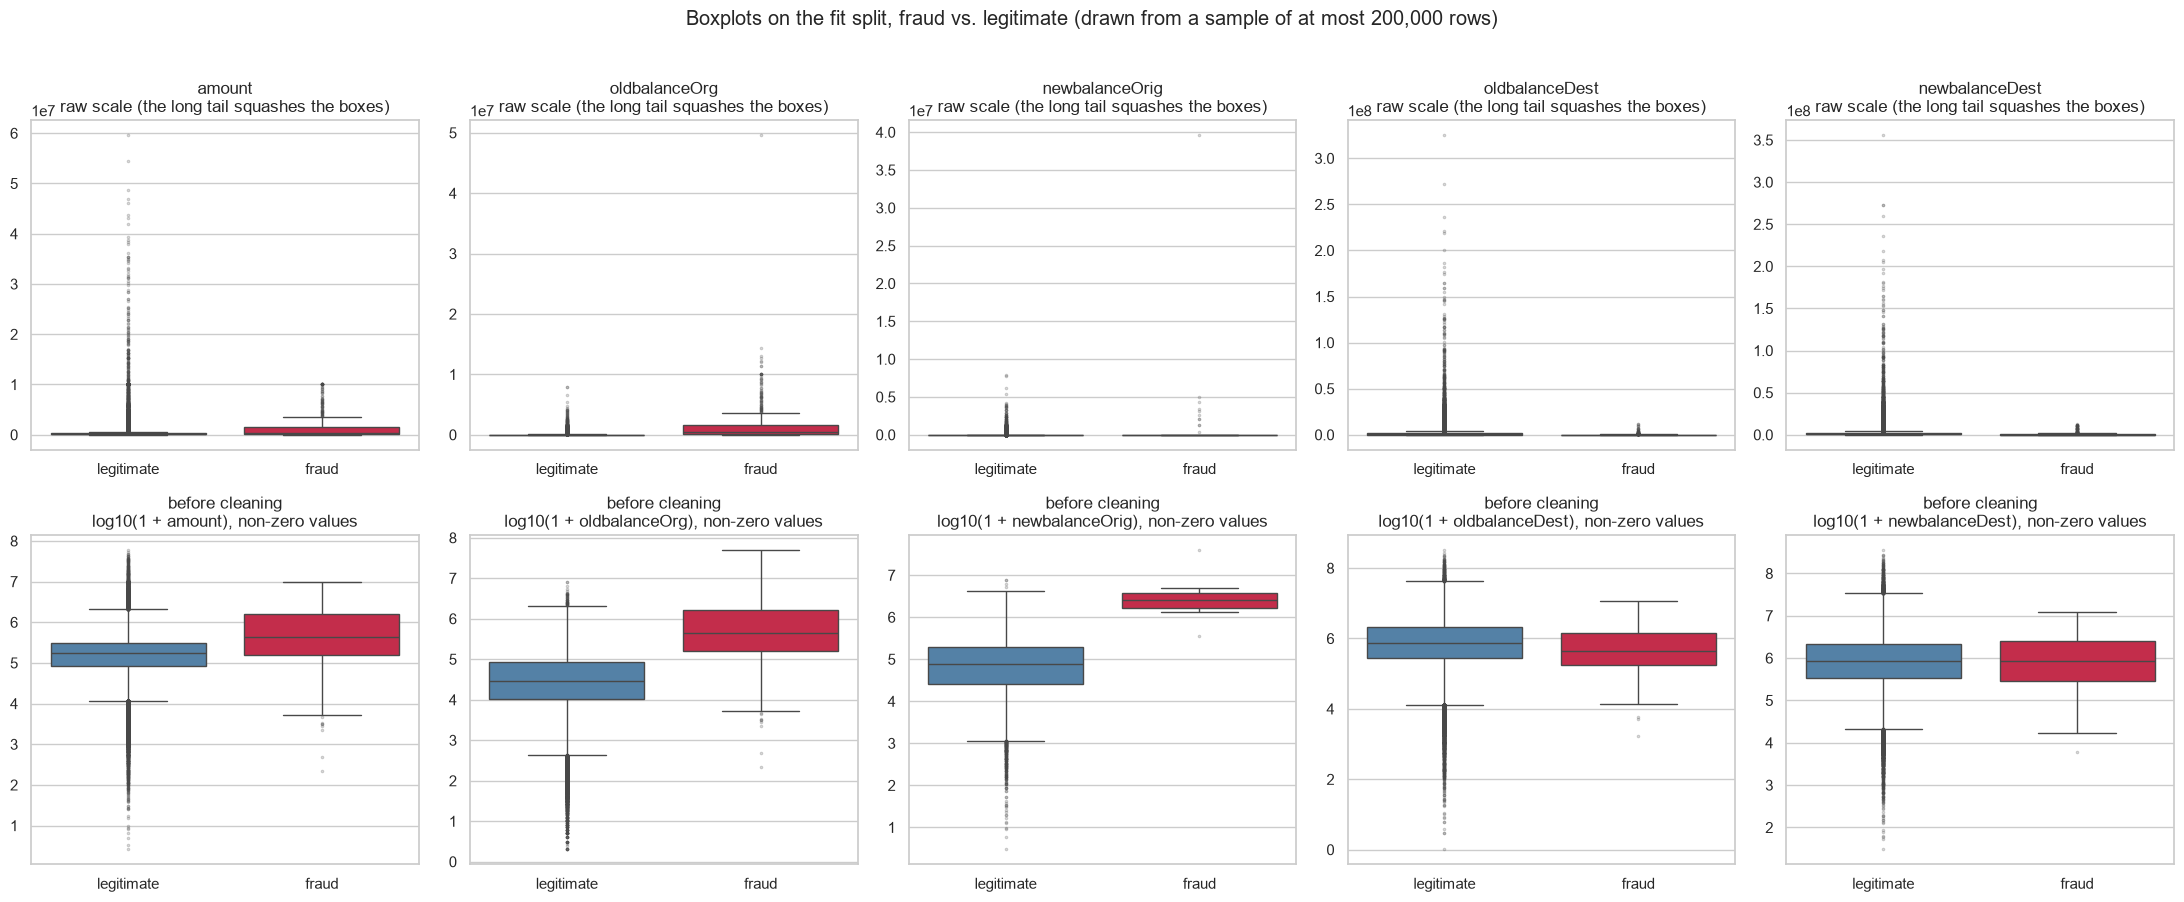

In [7]:
label_names = np.where(y_fit.to_numpy() == 1, "fraud", "legitimate")
plot_data = X_fit[money_cols].assign(label=label_names).sample(min(200_000, len(X_fit)), random_state=RANDOM_STATE)  # drawing only
palette = {"legitimate": "steelblue", "fraud": "crimson"}
order = ["legitimate", "fraud"]
flier_style = {"markersize": 1.5, "alpha": 0.3}


def log_boxplots(frame, axes_row, caption):
    # boxplots of log10(1 + value) for the NON-ZERO values of every money column, split by class
    for j, col in enumerate(money_cols):
        positive = frame[frame[col] > 0]
        sns.boxplot(x=positive["label"], y=np.log10(1 + positive[col]), order=order, hue=positive["label"],
                    palette=palette, legend=False, flierprops=flier_style, ax=axes_row[j])
        axes_row[j].set(title=f"{caption}\nlog10(1 + {col}), non-zero values", xlabel="", ylabel="")


zero_share = pd.DataFrame({col: (X_fit[col] == 0).groupby(y_fit.to_numpy()).mean() * 100 for col in money_cols}).T
zero_share.columns = ["zeros among legitimate (%)", "zeros among fraud (%)"]
print("Share of exact zeros per column (a legitimate state for balances; never an outlier):")
display(zero_share.round(2))

fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for j, col in enumerate(money_cols):
    sns.boxplot(data=plot_data, x="label", y=col, order=order, hue="label", palette=palette, legend=False,
                flierprops=flier_style, ax=axes[0, j])
    axes[0, j].set(title=f"{col}\nraw scale (the long tail squashes the boxes)", xlabel="", ylabel="")
log_boxplots(plot_data, axes[1], "before cleaning")
fig.suptitle("Boxplots on the fit split, fraud vs. legitimate (drawn from a sample of at most 200,000 rows)", y=1.0)
plt.tight_layout()
plt.show()

In [8]:
def whisker_bounds(values, whisker=1.5):
    q1, q3 = np.percentile(values, [25, 75])
    iqr = q3 - q1
    return q1 - whisker * iqr, q3 + whisker * iqr


is_fraud_fit = y_fit.to_numpy() == 1
log_outlier_flags, rows = {}, []
for col in money_cols:
    values = X_fit[col].to_numpy(dtype=float)
    positive = values > 0
    raw_low, raw_high = whisker_bounds(values[positive])
    raw_outlier = positive & ((values < raw_low) | (values > raw_high))
    log_values = np.log10(1 + values[positive])
    low, high = whisker_bounds(log_values)
    flags = np.zeros(len(values), dtype=bool)
    flags[positive] = (log_values < low) | (log_values > high)                  # zeros are never outliers
    log_outlier_flags[col] = flags
    rows.append({
        "feature": col,
        "outliers, raw-scale rule (%)": round(raw_outlier.mean() * 100, 2),
        "outliers, log-scale rule (%)": round(flags.mean() * 100, 3),
        "upper fence, log rule": round(10 ** high - 1),
        "outliers among frauds (%)": round(flags[is_fraud_fit].mean() * 100, 3),
        "outliers among legitimate (%)": round(flags[~is_fraud_fit].mean() * 100, 3),
        "fraud rate inside outliers (%)": round(is_fraud_fit[flags].mean() * 100, 3) if flags.any() else np.nan,
        "fraud rate outside outliers (%)": round(is_fraud_fit[~flags].mean() * 100, 3),
    })
display(pd.DataFrame(rows).set_index("feature"))

any_outlier = np.logical_or.reduce(list(log_outlier_flags.values()))
print(f"Rows that are an outlier in at least one money column: {any_outlier.mean():.2%} of the fit split.")
print(f"If those rows were DELETED, {is_fraud_fit[any_outlier].sum():,} of {is_fraud_fit.sum():,} frauds "
      f"({is_fraud_fit[any_outlier].sum() / max(is_fraud_fit.sum(), 1):.1%}) would disappear from the training data "
      f"and the fraud rate would change from {is_fraud_fit.mean():.3%} to {is_fraud_fit[~any_outlier].mean():.3%}.")

,"outliers, raw-scale rule (%)","outliers, log-scale rule (%)","upper fence, log rule",outliers among frauds (%),outliers among legitimate (%),fraud rate inside outliers (%),fraud rate outside outliers (%)
feature,,,,,,,
amount,8.04,4.737,2175520,22.630,4.684,1.416,0.241
oldbalanceOrg,5.74,3.378,2210291,18.815,3.332,1.651,0.249
newbalanceOrig,0.73,0.158,4437200,1.096,0.155,2.058,0.294
oldbalanceDest,8.65,1.647,43077326,1.441,1.647,0.259,0.297
newbalanceDest,9.91,1.194,34607023,0.893,1.195,0.222,0.297


Rows that are an outlier in at least one money column: 9.83% of the fit split.
If those rows were DELETED, 1,181 of 4,927 frauds (24.0%) would disappear from the training data and the fraud rate would change from 0.296% to 0.250%.


Effect of winsorizing (fences from the fit split):


,values capped (%),capped values in fraud rows (%),max before,max after
amount,1.396,18.855,9.244552e+07,2.175520e+06
oldbalanceOrg,0.079,18.551,5.958504e+07,2.210291e+06
newbalanceOrig,0.006,1.096,4.958504e+07,4.437200e+06
oldbalanceDest,0.109,0.020,3.560159e+08,4.307733e+07
newbalanceDest,0.232,0.041,3.561793e+08,3.460702e+07


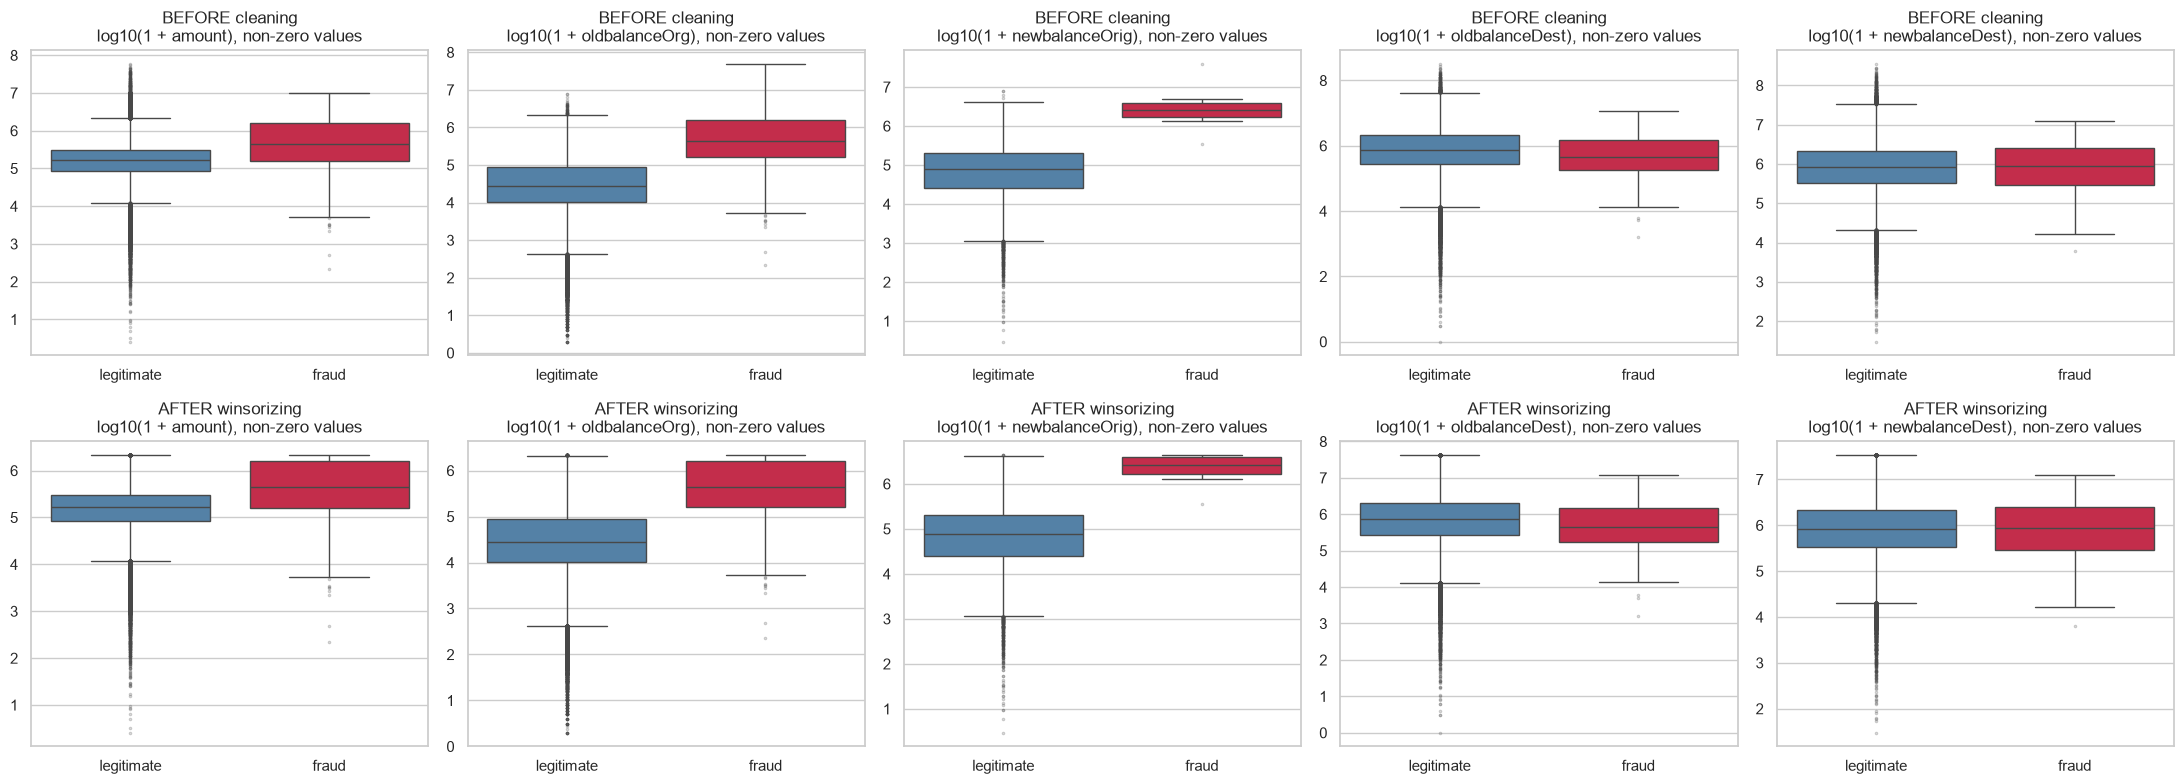

In [9]:
# Cleaning by winsorizing (capping at the boxplot whisker): fences are learned on the FIT split only, no rows are removed.
capper = OutlierCapper(whisker=1.5).fit(X_fit[money_cols].to_numpy(dtype=float))
before = X_fit[money_cols].to_numpy(dtype=float)
after = capper.transform(before)
capped = after != before
cleaning_summary = pd.DataFrame({
    "values capped (%)": (capped.mean(axis=0) * 100).round(3),
    "capped values in fraud rows (%)": [round(capped[is_fraud_fit, j].mean() * 100, 3) for j in range(len(money_cols))],
    "max before": before.max(axis=0), "max after": after.max(axis=0),
}, index=money_cols)
print("Effect of winsorizing (fences from the fit split):")
display(cleaning_summary)

cleaned_fit = X_fit.copy()
cleaned_fit[money_cols] = after
cleaned_plot = cleaned_fit[money_cols].assign(label=label_names).loc[plot_data.index]
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
log_boxplots(plot_data, axes[0], "BEFORE cleaning")
log_boxplots(cleaned_plot, axes[1], "AFTER winsorizing")
plt.tight_layout()
plt.show()

### Reading the outlier results (and the decision)
* **How many outliers?** Read the table: on a log scale only a small share of values is flagged, but on the raw scale a large
  share is (the raw rule mistakes an ordinary right-skewed distribution for "many outliers"). Zeros are excluded.
* **Are they errors?** The validity check looks for genuine data errors (negative or non-finite values, duplicates). Large
  amounts and balances that pass this check are valid simulated values, not mistakes.
* **Are they the fraud signal?** Compare *fraud rate inside outliers* with *outside outliers*, and see how many frauds would be
  lost by deleting outlier rows. If a large share of the frauds sits among the outliers, deleting rows would remove exactly the
  cases the model must learn - so **no rows are deleted**.
* **Why only the upper tail is capped:** the few very small positive values that remain as points in the "AFTER" plots are kept on purpose.
  They do not distort scale-sensitive models, and tiny amounts can themselves be informative (for example test transactions before a large fraud).
* **What was cleaned?** Invalid rows (if any) from the fit split, and the extreme upper tail of valid values by winsorizing. Ablation D
  in section 16 compares the model with and without this capping on validation data; `CAP_OUTLIERS` stays `False` unless it
  helps. Fences are always learned from training data (inside the pipeline: from the training fold).

## 5 · Feature engineering and preprocessing pipeline
All logic lives in `paysim_features.py`, the **same module** used by the notebook, the saved model and the Streamlit app.

| Group | Features | Needs post-transaction information? |
|---|---|---|
| Base | `amount`, `log_amount`, `type` (one-hot) | no |
| Pre-transaction balances | `is_account_emptied`, `amount_to_oldbalance_orig`, `is_orig_zero_start`, `is_dest_zero_start` | no (old balances only) |
| Time (from `step`) | `day_of_month`, `hour_of_day`, `is_night_window` | no, but hour features are a simulator artefact |
| **Post-transaction** | `balance_change_orig`, `orig_balance_diff`, `balance_change_dest`, `dest_balance_diff`, `dest_change_ratio`, `is_dest_zero_both` | **yes** (use `newbalance*`) |

Imputation, scaling and encoding are inside the scikit-learn `Pipeline`, so they are fitted on training folds only
(also inside cross-validation).
An optional `OutlierCapper` step (winsorizing at the boxplot whiskers, section 4b) can be inserted before scaling with
`CAP_OUTLIERS = True`; it is off by default.

In [10]:
# Sanity checks of the engineered features on a sample of the fit split
fe = PaySimFeatureEngineer()
sample_fe = fe.transform(X_fit.sample(min(200_000, len(X_fit)), random_state=RANDOM_STATE))
engineered = [c for c in sample_fe.columns if c != "type"]
non_finite = int((~np.isfinite(sample_fe[engineered].to_numpy(dtype=float))).sum())
print(f"non-finite engineered values in the sample: {non_finite}")
assert non_finite == 0
display(sample_fe[engineered].describe().T[["mean", "std", "min", "max"]])

non-finite engineered values in the sample: 0


,mean,std,min,max
amount,315725.224589,8.768340e+05,0.00,5.957950e+07
log_amount,11.928026,1.231178e+00,0.00,1.790282e+01
is_account_emptied,0.002780,5.265250e-02,0.00,1.000000e+00
amount_to_oldbalance_orig,59.077511,4.580177e+01,0.00,1.000000e+02
is_orig_zero_start,0.471330,4.991786e-01,0.00,1.000000e+00
is_dest_zero_start,0.140910,3.479296e-01,0.00,1.000000e+00
day_of_month,10.417665,5.878623e+00,1.00,3.100000e+01
hour_of_day,15.301230,4.007402e+00,0.00,2.300000e+01
is_night_window,0.001755,4.185605e-02,0.00,1.000000e+00
balance_change_orig,-31442.691406,1.580620e+05,-10000000.00,0.000000e+00


## 6 · Class-imbalance strategy
* Fraud is a tiny minority. To keep model comparison and hyper-parameter search fast, a **tuning set** is built from the
  **fit split only**: all frauds plus a random sample of legitimate rows (at most `UNDERSAMPLE_LEGIT_N`).
* **No `class_weight`, no SMOTE / synthetic oversampling.** The undersampling already rebalances the tuning set; a second
  correction on top of it would distort the probabilities.
* The undersampled data is used **only** for the model comparison and the hyper-parameter search. The **final model is
  refit on the complete natural-distribution fit split**, and every validation / test metric uses natural-prevalence data.
* Because the CV folds are undersampled, **CV metrics are not comparable** with validation or test metrics.

In [11]:
n_legit_us = min(UNDERSAMPLE_LEGIT_N, int((y_fit == 0).sum()))
legit_idx = y_fit[y_fit == 0].sample(n=n_legit_us, random_state=RANDOM_STATE).index
us_idx = y_fit[y_fit == 1].index.union(legit_idx)
X_us = X_fit.loc[us_idx].sample(frac=1.0, random_state=RANDOM_STATE)      # shuffled
y_us = y_fit.loc[X_us.index]

assert X_us.index.isin(X_fit.index).all(), "tuning data must be a subset of the fit split"
print(f"fit split (natural prevalence): {len(X_fit):,} rows, {y_fit.mean():.4%} fraud")
print(f"undersampled tuning set:        {len(X_us):,} rows, {y_us.mean():.2%} fraud")

fit split (natural prevalence): 1,662,245 rows, 0.2964% fraud
undersampled tuning set:        154,927 rows, 3.18% fraud


## 7 · Model comparison
Five candidates, each inside the same `Pipeline`, so imputation / scaling / encoding are re-fitted inside every CV fold.
* **CV column:** mean ± std of PR-AUC over 5 stratified folds of the **undersampled** tuning set.
* **Validation columns:** the model fitted on the whole tuning set, scored on the **natural-distribution validation split**.
  These are the numbers to compare across models.
* Precision / recall / F1 at a 0.5 cut-off on undersampled folds describe the wrong distribution, so they are not shown.
  "Best F1" uses the F1-maximising threshold *on validation* and measures capability, not a deployable result.
* Per-fold scores are printed because a mean can hide a fold that failed.

done: 1. Baseline (majority class) (14s)
done: 2. Logistic Regression (61s)
done: 3. Decision Tree (14s)
done: 4. Random Forest (122s)
done: 5. LightGBM (default) (31s)


,Model,"CV PR-AUC (mean ± std, undersampled folds)",Val PR-AUC (natural),Val ROC-AUC,Val best F1 (threshold tuned on val),Time (s)
0,4. Random Forest,0.9979 ± 0.0013,0.9977,0.9997,0.9988,122.4
1,2. Logistic Regression,0.9959 ± 0.0021,0.9975,0.9979,0.9976,61.4
2,5. LightGBM (default),0.9981 ± 0.0012,0.9961,0.9989,0.9979,30.5
3,3. Decision Tree,0.9956 ± 0.0023,0.9879,0.9990,0.9936,14.2
4,1. Baseline (majority class),0.0318 ± 0.0000,0.0030,0.5000,0.0059,14.4


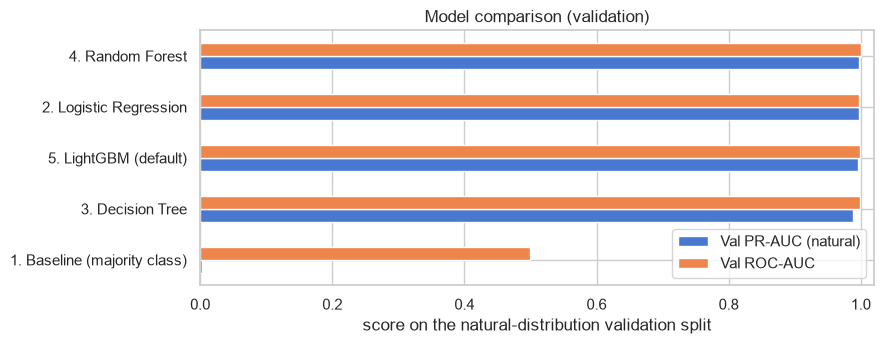

Per-fold CV PR-AUC:


,fold 1,fold 2,fold 3,fold 4,fold 5
1. Baseline (majority class),0.0318,0.0318,0.0318,0.0318,0.0318
2. Logistic Regression,0.9981,0.9981,0.9957,0.9953,0.9926
3. Decision Tree,0.9966,0.9982,0.9974,0.9941,0.9919
4. Random Forest,0.9990,0.9990,0.9984,0.9971,0.9958
5. LightGBM (default),0.9994,0.9996,0.9978,0.9966,0.9970


In [12]:
def best_f1(y_true, score):
    precision, recall, _ = precision_recall_curve(y_true, score)
    return float((2 * precision * recall / np.clip(precision + recall, 1e-12, None)).max())


candidates = {
    "1. Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
    "2. Logistic Regression": LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
    "3. Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
    "4. Random Forest": RandomForestClassifier(n_estimators=100, max_depth=12, random_state=RANDOM_STATE, n_jobs=1),
    "5. LightGBM (default)": LGBMClassifier(n_estimators=150, n_jobs=1, **LGBM_PARAMS),
}
scoring = {"pr_auc": "average_precision", "roc_auc": "roc_auc"}

# Logistic Regression is only a baseline; with heavy-tailed balance features it can hit its iteration limit.
# Only this ONE warning category is silenced (here and in the parallel CV workers); all other warnings stay visible.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
os.environ["PYTHONWARNINGS"] = "ignore::sklearn.exceptions.ConvergenceWarning"

leaderboard, fold_scores = [], {}
for name, estimator in candidates.items():
    started = time.time()
    pipe = Pipeline([("prep", make_preprocessing()), ("classifier", estimator)])
    scores = cross_validate(pipe, X_us, y_us, cv=CV, scoring=scoring, n_jobs=-1)   # folds run in parallel
    pipe.fit(X_us, y_us)
    val_score = pipe.predict_proba(X_val)[:, 1]
    fold_scores[name] = scores["test_pr_auc"]
    leaderboard.append({
        "Model": name,
        "CV PR-AUC (mean ± std, undersampled folds)": f"{scores['test_pr_auc'].mean():.4f} ± {scores['test_pr_auc'].std():.4f}",
        "Val PR-AUC (natural)": round(average_precision_score(y_val, val_score), 4),
        "Val ROC-AUC": round(roc_auc_score(y_val, val_score), 4),
        "Val best F1 (threshold tuned on val)": round(best_f1(y_val, val_score), 4),
        "Time (s)": round(time.time() - started, 1),
    })
    print(f"done: {name} ({time.time() - started:.0f}s)")

board = pd.DataFrame(leaderboard).sort_values("Val PR-AUC (natural)", ascending=False).reset_index(drop=True)
display(board)
ax = board.set_index("Model")[["Val PR-AUC (natural)", "Val ROC-AUC"]].iloc[::-1].plot.barh(figsize=(9, 3.6))
ax.set(xlabel="score on the natural-distribution validation split", ylabel="", title="Model comparison (validation)", xlim=(0, 1.02))
plt.tight_layout()
plt.show()
fold_table = pd.DataFrame(fold_scores).T.round(4)
fold_table.columns = [f"fold {i + 1}" for i in range(fold_table.shape[1])]
print("Per-fold CV PR-AUC:")
display(fold_table)
unstable = [name for name, s in fold_scores.items() if s.std() > 0.05]
if unstable:
    print("WARNING: large fold-to-fold variation for", unstable,
          "- a fold may have failed; inspect it before trusting the mean.")

### Reading the leaderboard
* Compare models on the **validation** columns. Differences in the third or fourth decimal of PR-AUC are far below the
  sampling noise of a validation set with only a few thousand frauds, so they do **not** rank the models.
* LightGBM is kept as the project model because the project direction was set to it (strong on tabular data, handles
  missing values natively, fast), not because it wins by a margin that is statistically meaningful.
* If a model shows a very large CV standard deviation, look at the per-fold table: it means at least one fold behaved
  very differently from the others (for example a failed fit), not that the model is "naturally variable".

## 8 · Hyper-parameter tuning (LightGBM)
* `RandomizedSearchCV` on the **undersampled tuning set only** (5-fold stratified CV, scoring = average precision,
  `N_ITER` candidates). Validation and test data are not touched.
* LightGBM ignores `subsample` unless `subsample_freq > 0`. The original run left `subsample_freq` at 0, which made
  `subsample` an inert hyper-parameter; here `subsample_freq=1` is fixed (see `LGBM_PARAMS`) so it works.
* With a handful of candidates the best few configurations are usually statistically tied; the table shows the spread.

In [13]:
lgbm_pipe = Pipeline([("prep", make_preprocessing()),
                      ("classifier", LGBMClassifier(n_jobs=1, **LGBM_PARAMS))])
param_distributions = {
    "classifier__n_estimators": [150, 250, 350],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__num_leaves": [31, 63, 127],
    "classifier__max_depth": [-1, 8, 12, 16],
    "classifier__min_child_samples": [20, 50, 100],
    "classifier__subsample": [0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.8, 0.9, 1.0],
    "classifier__reg_alpha": [0.0, 0.1, 1.0],
    "classifier__reg_lambda": [0.0, 0.1, 1.0],
}
random_search = RandomizedSearchCV(
    lgbm_pipe, param_distributions, n_iter=N_ITER, scoring="average_precision", cv=CV,
    random_state=RANDOM_STATE, n_jobs=-1, refit=False, verbose=1,
)
random_search.fit(X_us, y_us)

best_params = random_search.best_params_
cv_best_pr_auc = float(random_search.best_score_)
print(f"Best CV PR-AUC on the undersampled tuning folds: {cv_best_pr_auc:.4f}  (NOT comparable with validation/test PR-AUC)")
print("Best hyper-parameters:")
for key, value in best_params.items():
    print(f"  {key}: {value}")
display(pd.DataFrame(random_search.cv_results_)[["rank_test_score", "mean_test_score", "std_test_score", "params"]]
        .sort_values("rank_test_score").head(5))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV PR-AUC on the undersampled tuning folds: 0.9981  (NOT comparable with validation/test PR-AUC)
Best hyper-parameters:
  classifier__subsample: 1.0
  classifier__reg_lambda: 0.1
  classifier__reg_alpha: 0.0
  classifier__num_leaves: 31
  classifier__n_estimators: 150
  classifier__min_child_samples: 50
  classifier__max_depth: 12
  classifier__learning_rate: 0.05
  classifier__colsample_bytree: 1.0


,rank_test_score,mean_test_score,std_test_score,params
7,1,0.998077,0.001154,"{'classifier__subsample': 1.0, 'classifier__re..."
0,2,0.998047,0.001285,"{'classifier__subsample': 1.0, 'classifier__re..."
6,3,0.998026,0.001134,"{'classifier__subsample': 0.9, 'classifier__re..."
9,4,0.998015,0.001255,"{'classifier__subsample': 1.0, 'classifier__re..."
5,5,0.997987,0.001063,"{'classifier__subsample': 0.8, 'classifier__re..."


## 9 · Final model: refit on the natural-distribution fit split
The tuned configuration is refit on the **whole fit split** (natural fraud rate, no class weights, no undersampling).
Everything from here on uses this model.

In [14]:
base_model = clone(lgbm_pipe).set_params(**best_params, classifier__n_jobs=-1)
started = time.time()
base_model.fit(X_fit, y_fit)
print(f"Refit on {len(X_fit):,} rows ({y_fit.mean():.4%} fraud) in {time.time() - started:.0f}s")

val_raw = base_model.predict_proba(X_val)[:, 1]
print(f"Validation PR-AUC (raw scores): {average_precision_score(y_val, val_raw):.4f} | "
      f"ROC-AUC: {roc_auc_score(y_val, val_raw):.4f}")

Refit on 1,662,245 rows (0.2964% fraud) in 45s
Validation PR-AUC (raw scores): 0.9979 | ROC-AUC: 0.9996


## 10 · Probability calibration (validation set only)
The app multiplies the score by the transaction amount to show an *expected loss*; that is only meaningful if the score
behaves like a probability. Training on the natural distribution without class weights is a precondition for that, but it
does **not guarantee** it: boosted trees are often over-confident at both extremes.

**Checks (validation set):** mean predicted probability vs. the actual fraud rate, Brier score against a constant-prevalence
reference, a reliability table and curve over probability bands.

**Decision rule (fixed in advance):** fit a sigmoid (Platt) calibrator on `logit(score)` and evaluate it **out-of-fold** on the
validation set (5 folds). It is adopted only if the out-of-fold log-loss improves by at least `CALIBRATION_MIN_GAIN`.
* The calibrator is **never fitted on the test set**.
* It is a monotonic two-parameter map, so it cannot change rankings (PR-AUC, ROC-AUC); it changes the probability scale,
  and therefore the numeric threshold and the expected-loss figures. Fitting it on the validation set that is also used to
  choose the threshold is acceptable for that reason: the threshold search simply runs on the calibrated scale.

fraud rate - fit: 0.2964% | validation: 0.2965%
mean predicted probability (validation, raw): 0.2970%  -> ratio to the observed rate: 1.002
Brier score: 1.015e-05 | constant-prevalence reference: 2.956e-03 | Brier skill: 0.997 | log-loss: 0.0001

Reliability table (validation, raw scores):


,n,fraud,mean_predicted,observed_rate
band,,,,
"[1e-06, 0.0001)",550692,4,0.000003,0.000007
"[0.0001, 0.001)",1557,0,0.000212,0.000000
"[0.001, 0.01)",169,0,0.002772,0.000000
"[0.01, 0.1)",16,0,0.046706,0.000000
"[0.1, 0.5)",7,0,0.288968,0.000000
"[0.5, 0.9)",2,0,0.636997,0.000000
"[0.9, 1.0)",1639,1639,0.999858,1.000000


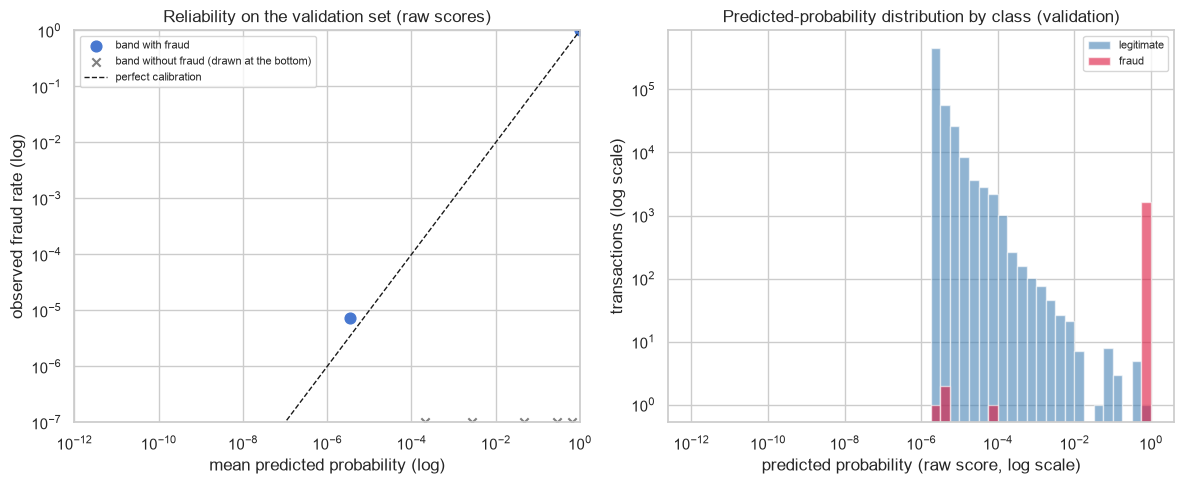


Out-of-fold log-loss: raw 0.0001 -> sigmoid-calibrated 0.0001 (relative gain 0.4%; adoption rule: >= 5%)
Out-of-fold Brier: raw 1.015e-05 -> calibrated 9.953e-06
-> calibration NOT adopted; the exported model returns the raw LightGBM scores.


In [15]:
y_val_np = y_val.to_numpy()
prevalence_fit, prevalence_val = float(y_fit.mean()), float(y_val.mean())
print(f"fraud rate - fit: {prevalence_fit:.4%} | validation: {prevalence_val:.4%}")
print(f"mean predicted probability (validation, raw): {val_raw.mean():.4%}  "
      f"-> ratio to the observed rate: {val_raw.mean() / prevalence_val:.3f}")

brier_raw = brier_score_loss(y_val, val_raw)
brier_reference = brier_score_loss(y_val, np.full(len(y_val), prevalence_fit))     # always predict the training prevalence
ll_raw = log_loss(y_val, np.clip(val_raw, 1e-15, 1 - 1e-15))
print(f"Brier score: {brier_raw:.3e} | constant-prevalence reference: {brier_reference:.3e} "
      f"| Brier skill: {1 - brier_raw / brier_reference:.3f} | log-loss: {ll_raw:.4f}")

edges = [0, 1e-6, 1e-4, 1e-3, 1e-2, 0.1, 0.5, 0.9, 1.0 + 1e-9]
band = pd.cut(val_raw, bins=edges, right=False)
reliability = (pd.DataFrame({"band": band, "p": val_raw, "y": y_val_np})
               .groupby("band", observed=True)
               .agg(n=("y", "size"), fraud=("y", "sum"), mean_predicted=("p", "mean"), observed_rate=("y", "mean")))
print("\nReliability table (validation, raw scores):")
display(reliability)

fig, (ax, ax_hist) = plt.subplots(1, 2, figsize=(12, 5))
positive = reliability["observed_rate"] > 0
ax.scatter(reliability.loc[positive, "mean_predicted"], reliability.loc[positive, "observed_rate"], s=60,
           label="band with fraud")
ax.scatter(reliability.loc[~positive, "mean_predicted"], np.full(int((~positive).sum()), 1e-7), marker="x",
           color="gray", label="band without fraud (drawn at the bottom)")
ax.plot([1e-12, 1], [1e-12, 1], "k--", linewidth=1, label="perfect calibration")
ax.set(xscale="log", yscale="log", xlim=(1e-12, 1), ylim=(1e-7, 1), xlabel="mean predicted probability (log)",
       ylabel="observed fraud rate (log)", title="Reliability on the validation set (raw scores)")
ax.legend(fontsize=8)
bins = np.logspace(-12, 0, 49)
clipped = np.clip(val_raw, 1e-12, 1.0)
ax_hist.hist(clipped[y_val_np == 0], bins=bins, alpha=0.6, color="steelblue", label="legitimate")
ax_hist.hist(clipped[y_val_np == 1], bins=bins, alpha=0.6, color="crimson", label="fraud")
ax_hist.set(xscale="log", yscale="log", xlabel="predicted probability (raw score, log scale)",
            ylabel="transactions (log scale)", title="Predicted-probability distribution by class (validation)")
ax_hist.legend(fontsize=8)
plt.tight_layout()
plt.show()

# ---- out-of-fold evaluation of a sigmoid calibrator on the validation set --------------------
oof = np.zeros(len(val_raw))
for fit_idx, held_idx in StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(val_raw, y_val_np):
    slope_k, intercept_k = fit_logit_platt(val_raw[fit_idx], y_val_np[fit_idx])
    oof[held_idx] = apply_logit_platt(val_raw[held_idx], slope_k, intercept_k)
ll_oof = log_loss(y_val, np.clip(oof, 1e-15, 1 - 1e-15))
calibration_gain = 1 - ll_oof / ll_raw
print(f"\nOut-of-fold log-loss: raw {ll_raw:.4f} -> sigmoid-calibrated {ll_oof:.4f} "
      f"(relative gain {calibration_gain:.1%}; adoption rule: >= {CALIBRATION_MIN_GAIN:.0%})")
print(f"Out-of-fold Brier: raw {brier_raw:.3e} -> calibrated {brier_score_loss(y_val, oof):.3e}")

APPLY_CALIBRATION = bool(calibration_gain >= CALIBRATION_MIN_GAIN)
if APPLY_CALIBRATION:
    cal_slope, cal_intercept = fit_logit_platt(val_raw, y_val_np)
    final_model = CalibratedPipeline(base_model, cal_slope, cal_intercept)
    print(f"-> calibration ADOPTED (slope {cal_slope:.3f}, intercept {cal_intercept:.3f}); the exported model returns calibrated probabilities.")
else:
    cal_slope = cal_intercept = None
    final_model = base_model
    print("-> calibration NOT adopted; the exported model returns the raw LightGBM scores.")
val_proba = final_model.predict_proba(X_val)[:, 1]

## 11 · Threshold selection and financial cost (validation set only)
* Total cost = **missed fraud amount + `FP_COST` × false alarms**. A missed fraud is priced at its full transaction amount
  (a *proxy* for the real loss); `FP_COST = 50` is an *assumption*, not a measured cost.
* The threshold is the **lowest** value that reaches the minimum validation cost (ties go toward higher recall, because a
  missed fraud costs its full amount while a false alarm costs `FP_COST`). The test set plays no role.
* When the model separates the classes almost perfectly, the cost curve is **flat over a wide range**: the shaded band is
  every threshold within one false alarm of the minimum, and the exact optimum can hinge on a handful of validation
  transactions. Read the chosen threshold as one point inside that band, not as a precise optimum.
* The cost model has **no alert-capacity constraint**. If the score is not near-separable and `FP_COST` is small compared
  with the fraud amounts, the cost optimum can be to flag most transactions; real review teams have limited capacity.

Selected review threshold (validation): 0.7700
Near-optimal band (within one false alarm of the minimum cost): 0.52 to 0.95
At the selected threshold on VALIDATION: alerts=1639, TP=1639, FP=0, FN=4, precision=1.0000, recall=0.9976
Validation total cost: 4,068,463 (no model: 2,432,284,791)


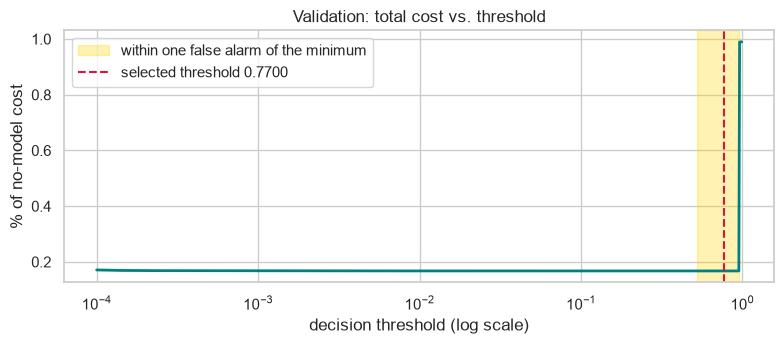

In [16]:
thresholds = np.unique(np.round(np.concatenate([np.logspace(-4, -1, 61), np.linspace(0.1, 0.99, 90)]), 6))
val_amount = X_val["amount"].to_numpy()
curve = cost_curve(y_val_np, val_proba, val_amount, FP_COST, thresholds)

THRESHOLD = select_threshold(curve)
near_low, near_high = near_optimal_range(curve, FP_COST)
no_model_val_cost = cost_of(y_val_np, np.zeros(len(y_val_np), bool), val_amount, FP_COST)["total_cost"]
chosen = curve.loc[curve["threshold"] == THRESHOLD].iloc[0]
print(f"Selected review threshold (validation): {THRESHOLD:.4f}")
print(f"Near-optimal band (within one false alarm of the minimum cost): {near_low:.4g} to {near_high:.4g}")
print(f"At the selected threshold on VALIDATION: alerts={int(chosen['alerts'])}, TP={int(chosen['TP'])}, "
      f"FP={int(chosen['FP'])}, FN={int(chosen['FN'])}, precision={chosen['precision']:.4f}, recall={chosen['recall']:.4f}")
print(f"Validation total cost: {chosen['total_cost']:,.0f} (no model: {no_model_val_cost:,.0f})")
if near_low <= thresholds.min() or near_high >= thresholds.max():
    print("NOTE: the near-optimal band reaches the edge of the threshold grid. Many thresholds are equivalent on this "
          "validation set (near-perfect separation), so the selected value is only one of them.")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(curve["threshold"], curve["total_cost"] / no_model_val_cost * 100, color="teal", linewidth=2)
ax.axvspan(near_low, near_high, color="gold", alpha=0.3, label="within one false alarm of the minimum")
ax.axvline(THRESHOLD, color="crimson", linestyle="--", label=f"selected threshold {THRESHOLD:.4f}")
ax.set(xscale="log", xlabel="decision threshold (log scale)", ylabel="% of no-model cost",
       title="Validation: total cost vs. threshold")
ax.legend()
plt.tight_layout()
plt.show()

,FP_COST,optimal threshold,near-optimal band,alerts,FP,FN,precision,recall,total cost
0,50,0.77,0.52 - 0.95,1639,0,4,1.0,0.9976,4068463
1,500,0.77,0.52 - 0.95,1639,0,4,1.0,0.9976,4068463
2,5000,0.77,0.52 - 0.95,1639,0,4,1.0,0.9976,4068463
3,50000,0.77,0.52 - 0.95,1639,0,4,1.0,0.9976,4068463
4,500000,0.77,0.52 - 0.95,1639,0,4,1.0,0.9976,4068463


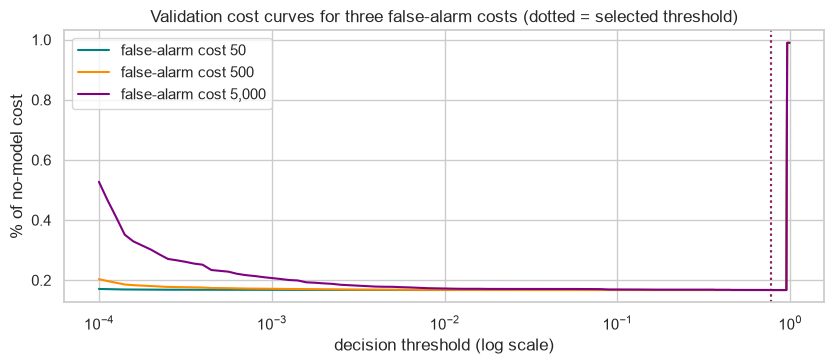

In [17]:
# Sensitivity to the (assumed) false-alarm cost. The threshold is re-picked on VALIDATION for every cost.
# 50 / 500 / 5,000 are the required scenarios; 50,000 / 500,000 show where the optimum starts to move.
rows = []
for fp in [50, 500, 5_000, 50_000, 500_000]:
    repriced = recost(curve, fp)
    t = select_threshold(repriced)
    low, high = near_optimal_range(repriced, fp)
    r = repriced.loc[repriced["threshold"] == t].iloc[0]
    rows.append({"FP_COST": fp, "optimal threshold": t, "near-optimal band": f"{low:.4g} - {high:.4g}",
                 "alerts": int(r["alerts"]), "FP": int(r["FP"]), "FN": int(r["FN"]),
                 "precision": round(r["precision"], 4), "recall": round(r["recall"], 4),
                 "total cost": round(r["total_cost"])})
sensitivity = pd.DataFrame(rows)
display(sensitivity)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
for fp, color in zip([50, 500, 5_000], ["teal", "darkorange", "purple"]):
    repriced = recost(curve, fp)
    ax.plot(repriced["threshold"], repriced["total_cost"] / no_model_val_cost * 100, color=color, label=f"false-alarm cost {fp:,}")
    ax.axvline(select_threshold(repriced), color=color, linestyle=":", alpha=0.8)
ax.set(xscale="log", xlabel="decision threshold (log scale)", ylabel="% of no-model cost",
       title="Validation cost curves for three false-alarm costs (dotted = selected threshold)")
ax.legend()
plt.tight_layout()
plt.show()

### Why different businesses need different thresholds
The best threshold depends on the ratio between the cost of a missed fraud and the cost of a false alarm. A bank where
every alert triggers an expensive manual review, or where blocking a customer is very costly, should accept more missed
fraud and use a **higher** threshold; a platform where an extra OTP challenge is almost free should use a **lower** one.
The sensitivity table shows how far the optimum actually moves **for this model**: when the model separates the classes
almost perfectly, the optimum barely changes over a wide range of costs; it moves only once the false-alarm cost
approaches the size of the frauds themselves. That is a property of PaySim's very clean fraud pattern, not a general rule.

## 12 · Three-tier decision policy
| Score `p` | Action |
|---|---|
| `p` < review threshold | **Approve** |
| review threshold ≤ `p` < block threshold | **Manual review** / step-up authentication |
| `p` ≥ block threshold | **Block** |

* The **review threshold** is the validation cost-optimal threshold from section 11.
* The **block threshold** (`BLOCK_THRESHOLD`) is a *business-policy* parameter. It was **not optimised** and is not claimed
  to be statistically optimal; it is configurable in the app. The table below shows what the policy does on validation data -
  judge the choice by the fraud share inside each tier.
* For cost accounting, every alert (review **or** block) is treated alike: a flagged fraud is prevented and a flagged legitimate
  transaction costs `FP_COST`.

In [18]:
def tier_table(y_true, proba, review_threshold, block_threshold, amount):
    tiers = pd.Series(decision_tier(proba, review_threshold, block_threshold), name="tier")
    frame = pd.DataFrame({"tier": tiers, "fraud": np.asarray(y_true), "amount": np.asarray(amount, dtype=float)})
    frame["fraud_amount"] = frame["amount"] * frame["fraud"]
    table = frame.groupby("tier").agg(transactions=("fraud", "size"), frauds=("fraud", "sum"),
                                      fraud_amount=("fraud_amount", "sum"))
    table = table.reindex(["Approve", "Manual Review", "Block"]).fillna(0)
    table[["transactions", "frauds"]] = table[["transactions", "frauds"]].astype(int)
    table["fraud_share_of_tier_%"] = (table["frauds"] / table["transactions"].replace(0, np.nan) * 100).round(3)
    return table


print(f"Policy on the VALIDATION set: review >= {THRESHOLD:.4f}, block >= {max(BLOCK_THRESHOLD, THRESHOLD):.4f}")
display(tier_table(y_val_np, val_proba, THRESHOLD, BLOCK_THRESHOLD, val_amount))

Policy on the VALIDATION set: review >= 0.7700, block >= 0.7700


,transactions,frauds,fraud_amount,fraud_share_of_tier_%
tier,,,,
Approve,552443,4,4.068463e+06,0.001
Manual Review,0,0,0.000000e+00,NaN
Block,1639,1639,2.428216e+09,100.000


## 13 · Final evaluation on the untouched test split (one shot)
The test split is used here for the first time. Everything from this point on is **reporting**: nothing is tuned,
selected or re-thresholded from it.

In [19]:
test_proba = final_model.predict_proba(X_test)[:, 1]
test_amount = X_test["amount"].to_numpy()
y_test_np = y_test.to_numpy()
test_pr_auc = float(average_precision_score(y_test_np, test_proba))
test_roc_auc = float(roc_auc_score(y_test_np, test_proba))
test_stats = cost_of(y_test_np, test_proba >= THRESHOLD, test_amount, FP_COST)
test_f1 = 2 * test_stats["precision"] * test_stats["recall"] / max(test_stats["precision"] + test_stats["recall"], 1e-12)

print(f"TEST PR-AUC: {test_pr_auc:.4f} | ROC-AUC: {test_roc_auc:.4f}")
print(f"TEST at the validation-chosen threshold {THRESHOLD:.4f}: TP={test_stats['TP']}, FP={test_stats['FP']}, "
      f"FN={test_stats['FN']} | precision={test_stats['precision']:.4f}, recall={test_stats['recall']:.4f}, F1={test_f1:.4f}")

compare = pd.DataFrame({
    "no model": cost_of(y_test_np, np.zeros(len(y_test_np), bool), test_amount, FP_COST),
    "legacy rule (isFlaggedFraud)": cost_of(y_test_np, X_test["isFlaggedFraud"].to_numpy() == 1, test_amount, FP_COST),
    "model @ validation threshold": test_stats,
    "flag everything": cost_of(y_test_np, np.ones(len(y_test_np), bool), test_amount, FP_COST),
}).T
print("\nCost comparison on the TEST split (missed fraud = full amount; false alarm = FP_COST):")
display(compare)
print("Three-tier policy on the TEST split:")
display(tier_table(y_test_np, test_proba, THRESHOLD, BLOCK_THRESHOLD, test_amount))

TEST PR-AUC: 0.9975 | ROC-AUC: 0.9996
TEST at the validation-chosen threshold 0.7700: TP=1637, FP=0, FN=6 | precision=1.0000, recall=0.9963, F1=0.9982

Cost comparison on the TEST split (missed fraud = full amount; false alarm = FP_COST):


,alerts,TP,FP,FN,precision,recall,missed_fraud_amount,false_alarm_cost,total_cost
no model,0.0,0.0,0.0,1643.0,0.000000,0.000000,2.427468e+09,0.0,2.427468e+09
legacy rule (isFlaggedFraud),3.0,3.0,0.0,1640.0,1.000000,0.001826,2.415726e+09,0.0,2.415726e+09
model @ validation threshold,1637.0,1637.0,0.0,6.0,1.000000,0.996348,1.798617e+06,0.0,1.798617e+06
flag everything,554082.0,1643.0,552439.0,0.0,0.002965,1.000000,0.000000e+00,27621950.0,2.762195e+07


Three-tier policy on the TEST split:


,transactions,frauds,fraud_amount,fraud_share_of_tier_%
tier,,,,
Approve,552445,6,1.798617e+06,0.001
Manual Review,0,0,0.000000e+00,NaN
Block,1637,1637,2.425669e+09,100.000


## 14 · Error analysis (interpretation only)
These tables and plots explain *where* the model fails. They are computed after the final evaluation and are **not** used to
change the model, the threshold or the features.

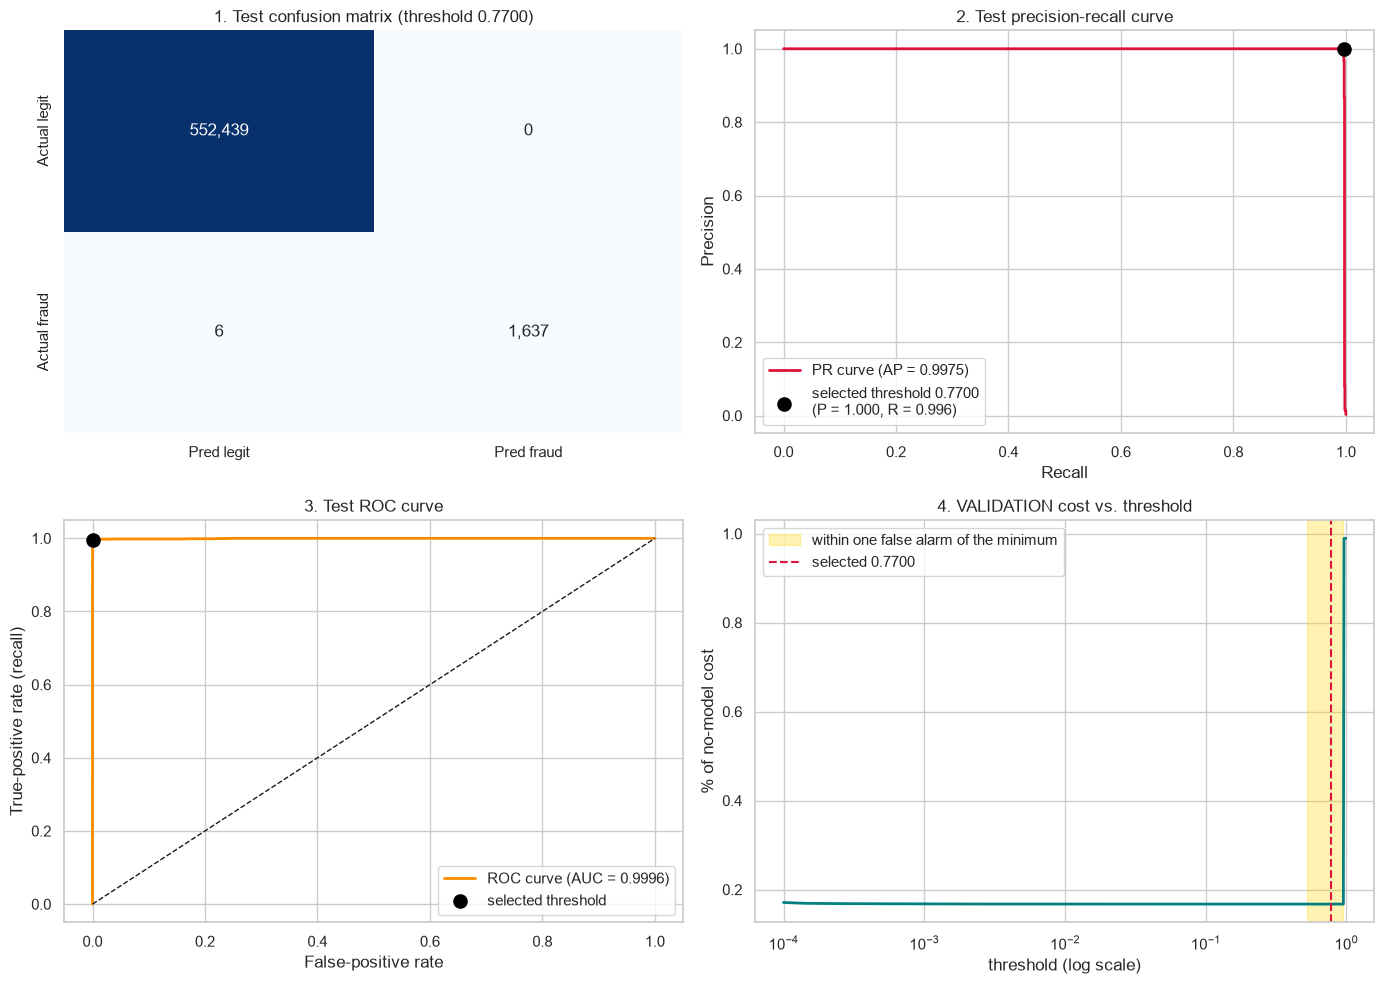

=== Summary by outcome group (test split) ===


,count,median amount,mean amount,% TRANSFER,% account emptied,% night window (hours 2-6)
Caught fraud (TP),1637.0,452261.67,1481777.30,50.03,98.05,21.44
Missed fraud (FN),6.0,258615.12,299769.56,50.00,0.00,0.00
False alarms (FP),0.0,NaN,NaN,NaN,NaN,NaN
True negatives (TN),552439.0,170981.18,314915.66,19.17,0.00,0.11



=== False negatives: the 10 most expensive missed frauds (sorted by amount) ===


,step,hour,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,proba
750755,38,14,CASH_OUT,577418.98,0.00,0.00,0.00,577418.98,0.006020
6281484,646,22,TRANSFER,399045.08,10399045.08,10399045.08,0.00,0.00,0.000638
408955,18,18,CASH_OUT,314251.58,75956.47,0.00,7962205.25,8276456.84,0.000003
1021951,47,23,TRANSFER,202978.65,0.00,0.00,2122336.55,2325315.19,0.000003
14861,8,8,CASH_OUT,181728.11,0.00,0.00,11397.00,184477.77,0.000010
217978,13,13,TRANSFER,123194.95,79466.45,0.00,535933.16,263908.84,0.000003


Missed frauds by type, by hour of day, and by account-emptying behaviour:


type,TRANSFER,CASH_OUT
missed frauds,3,3


hour,8,13,14,18,22,23
missed frauds per hour,1,1,1,1,1,1


is_account_emptied,0
missed frauds (1 = account emptied),6



=== False positives: the 10 highest-scoring false alarms ===
No false alarms on the test split.


In [20]:
test_flag = test_proba >= THRESHOLD
precision_curve, recall_curve, _ = precision_recall_curve(y_test_np, test_proba)

fpr, tpr, _ = roc_curve(y_test_np, test_proba)
fpr_selected = test_stats["FP"] / max(int((y_test_np == 0).sum()), 1)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.heatmap(confusion_matrix(y_test_np, test_flag), annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0, 0],
            xticklabels=["Pred legit", "Pred fraud"], yticklabels=["Actual legit", "Actual fraud"])
axes[0, 0].set_title(f"1. Test confusion matrix (threshold {THRESHOLD:.4f})")
axes[0, 1].plot(recall_curve, precision_curve, color="crimson", linewidth=2, label=f"PR curve (AP = {test_pr_auc:.4f})")
axes[0, 1].scatter([test_stats["recall"]], [test_stats["precision"]], color="black", s=90, zorder=5,
                   label=f"selected threshold {THRESHOLD:.4f}\n(P = {test_stats['precision']:.3f}, R = {test_stats['recall']:.3f})")
axes[0, 1].set(title="2. Test precision-recall curve", xlabel="Recall", ylabel="Precision")
axes[0, 1].legend(loc="lower left")
axes[1, 0].plot(fpr, tpr, color="darkorange", linewidth=2, label=f"ROC curve (AUC = {test_roc_auc:.4f})")
axes[1, 0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[1, 0].scatter([fpr_selected], [test_stats["recall"]], color="black", s=90, zorder=5, label="selected threshold")
axes[1, 0].set(title="3. Test ROC curve", xlabel="False-positive rate", ylabel="True-positive rate (recall)")
axes[1, 0].legend(loc="lower right")
axes[1, 1].plot(curve["threshold"], curve["total_cost"] / no_model_val_cost * 100, color="teal", linewidth=2)
axes[1, 1].axvspan(near_low, near_high, color="gold", alpha=0.3, label="within one false alarm of the minimum")
axes[1, 1].axvline(THRESHOLD, color="crimson", linestyle="--", label=f"selected {THRESHOLD:.4f}")
axes[1, 1].set(xscale="log", title="4. VALIDATION cost vs. threshold", xlabel="threshold (log scale)", ylabel="% of no-model cost")
axes[1, 1].legend()
plt.tight_layout()
plt.show()

eval_df = X_test.assign(y_true=y_test_np, proba=test_proba, pred=test_flag.astype(int))
eval_df["hour"] = eval_df["step"] % 24
eval_df["is_account_emptied"] = ((eval_df["amount"] == eval_df["oldbalanceOrg"]) & (eval_df["oldbalanceOrg"] > 0)).astype(int)
eval_df["night_window"] = eval_df["hour"].between(2, 6).astype(int)
groups = {
    "Caught fraud (TP)": (eval_df["y_true"] == 1) & (eval_df["pred"] == 1),
    "Missed fraud (FN)": (eval_df["y_true"] == 1) & (eval_df["pred"] == 0),
    "False alarms (FP)": (eval_df["y_true"] == 0) & (eval_df["pred"] == 1),
    "True negatives (TN)": (eval_df["y_true"] == 0) & (eval_df["pred"] == 0),
}


def summarize(sub):
    n = len(sub)
    nan = np.nan
    return pd.Series({
        "count": n,
        "median amount": sub["amount"].median() if n else nan,
        "mean amount": sub["amount"].mean() if n else nan,
        "% TRANSFER": (sub["type"] == "TRANSFER").mean() * 100 if n else nan,
        "% account emptied": sub["is_account_emptied"].mean() * 100 if n else nan,
        "% night window (hours 2-6)": sub["night_window"].mean() * 100 if n else nan,
    })


print("=== Summary by outcome group (test split) ===")
display(pd.DataFrame({name: summarize(eval_df[mask]) for name, mask in groups.items()}).T.round(2))

columns = ["step", "hour", "type", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "proba"]
fn_df, fp_df = eval_df[groups["Missed fraud (FN)"]], eval_df[groups["False alarms (FP)"]]
print("\n=== False negatives: the 10 most expensive missed frauds (sorted by amount) ===")
if len(fn_df):
    display(fn_df[columns].sort_values("amount", ascending=False).head(10))
    print("Missed frauds by type, by hour of day, and by account-emptying behaviour:")
    display(fn_df["type"].value_counts().rename("missed frauds").to_frame().T)
    display(fn_df["hour"].value_counts().sort_index().rename("missed frauds per hour").to_frame().T)
    display(fn_df["is_account_emptied"].value_counts().rename("missed frauds (1 = account emptied)").to_frame().T)
else:
    print("No missed frauds on the test split.")
print("\n=== False positives: the 10 highest-scoring false alarms ===")
if len(fp_df):
    display(fp_df[columns].sort_values("proba", ascending=False).head(10))
    print("False alarms by type and amount:")
    display(fp_df.groupby("type")["amount"].agg(["count", "median", "max"]))
else:
    print("No false alarms on the test split.")

## 15 · Feature importance (LightGBM gain)
Importance = total split gain per feature, shown as a share of the total. Importance describes how the model uses its
inputs; it is **not** a causal statement about fraud. If one feature carries almost all the gain, the model behaves
almost like a one-feature rule - compare it with the rule baseline in the ablation below.

,feature,gain,gain share (%)
0,is_account_emptied,1.610716e+06,98.4790
1,dest_balance_diff,1.603545e+04,0.9804
2,balance_change_orig,1.687170e+03,0.1032
3,day_of_month,1.162809e+03,0.0711
4,is_dest_zero_both,1.040373e+03,0.0636
5,dest_change_ratio,9.113927e+02,0.0557
6,amount,8.744712e+02,0.0535
7,orig_balance_diff,6.728608e+02,0.0411
8,hour_of_day,6.594464e+02,0.0403
9,balance_change_dest,6.129973e+02,0.0375


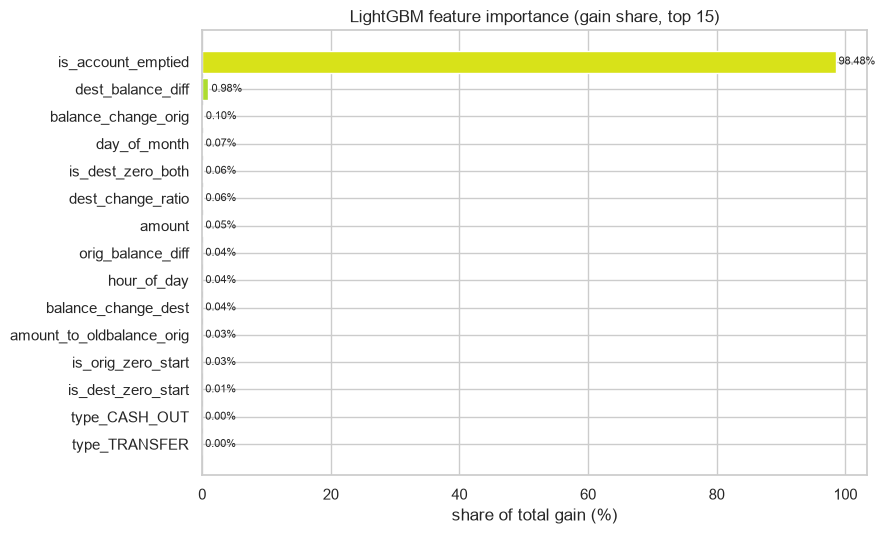

In [21]:
gain = base_model.named_steps["classifier"].booster_.feature_importance(importance_type="gain")
importance = pd.DataFrame({"feature": model_feature_names(base_model.named_steps["prep"]), "gain": gain})
importance["gain share (%)"] = importance["gain"] / importance["gain"].sum() * 100
importance = importance.sort_values("gain", ascending=False).reset_index(drop=True)
display(importance.head(15).round(4))

top = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top["feature"], top["gain share (%)"], color=sns.color_palette("viridis", len(top)))
for position, value in enumerate(top["gain share (%)"]):
    ax.text(value, position, f" {value:.2f}%", va="center", fontsize=8)
ax.set(xlabel="share of total gain (%)", title="LightGBM feature importance (gain share, top 15)")
plt.tight_layout()
plt.show()

## 16 · Ablation study (validation set only)
Same hyper-parameters, same fit split, same validation split for every variant - no test data, no re-tuning:

| Variant | Question it answers |
|---|---|
| **A** full model | reference |
| **B** without post-transaction features | how much depends on information that only exists *after* execution, i.e. is a **pre-authorisation** model realistic? |
| **C** without hour features | how much does the model lean on the simulator's hour artefact? |
| **D** opposite outlier-capping setting | does winsorizing the heavy-tailed features (section 4b) help? Adopt it only if validation improves by more than the noise margin |
| **Rule baseline** | score = `is_account_emptied` alone (no model): a sanity anchor |

The EDA says that `is_account_emptied` is a **pre-transaction** feature that separates most fraud from legitimate rows.
Variant B still contains it, so B should not score far *below* this single-feature rule. If it does, investigate the fit
(for example a failed LightGBM run) before drawing conclusions about deployability.
Ablation results are **not** used to choose features for the final model.

,Variant,# features,Val PR-AUC,Val ROC-AUC
0,(A) Full model (all features),17,0.9979,0.9996
1,(B) Pre-transaction features only (no post-tra...,11,0.9977,0.9996
2,(C) Without hour features,15,0.9980,0.9996
3,(D) Full model with outlier capping ON (opposi...,17,0.9979,0.9997
4,Rule baseline: is_account_emptied only (no model),1,0.9769,0.9884


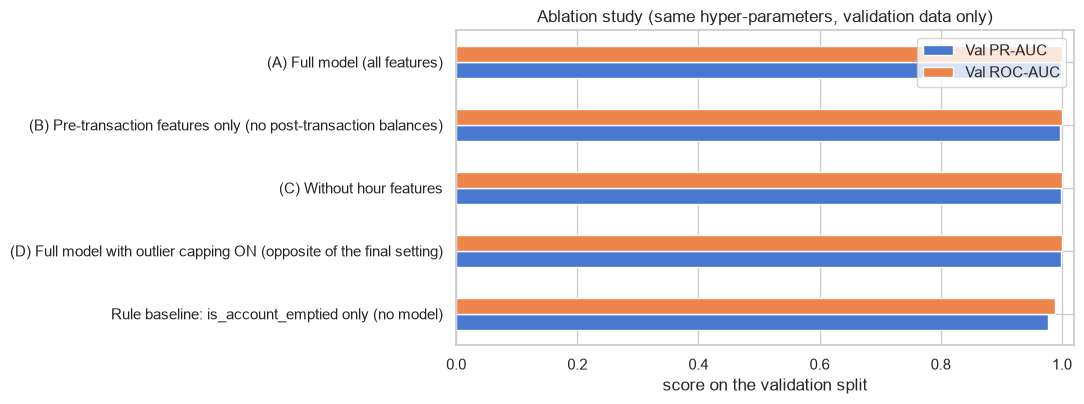

In [22]:
search_params = {key.replace("classifier__", ""): value for key, value in best_params.items()}
ablation_configs = [
    ("(A) Full model (all features)", True, True, CAP_OUTLIERS),
    ("(B) Pre-transaction features only (no post-transaction balances)", False, True, CAP_OUTLIERS),
    ("(C) Without hour features", True, False, CAP_OUTLIERS),
    (f"(D) Full model with outlier capping {'OFF' if CAP_OUTLIERS else 'ON'} (opposite of the final setting)", True, True, not CAP_OUTLIERS),
]
rows = []
for label, include_post_tx, include_hour, cap_outliers in ablation_configs:
    ablation_model = Pipeline([
        ("prep", build_preprocessing_pipeline(include_post_tx=include_post_tx, include_hour=include_hour,
                                              cap_outliers=cap_outliers)),
        ("classifier", LGBMClassifier(n_jobs=-1, **LGBM_PARAMS, **search_params)),
    ]).fit(X_fit, y_fit)
    p_ablation = ablation_model.predict_proba(X_val)[:, 1]
    rows.append({"Variant": label,
                 "# features": len(model_feature_names(ablation_model.named_steps["prep"])),
                 "Val PR-AUC": round(average_precision_score(y_val_np, p_ablation), 4),
                 "Val ROC-AUC": round(roc_auc_score(y_val_np, p_ablation), 4)})

rule_score = PaySimFeatureEngineer().transform(X_val)["is_account_emptied"].to_numpy(dtype=float)
rows.append({"Variant": "Rule baseline: is_account_emptied only (no model)", "# features": 1,
             "Val PR-AUC": round(average_precision_score(y_val_np, rule_score), 4),
             "Val ROC-AUC": round(roc_auc_score(y_val_np, rule_score), 4)})
ablation_table = pd.DataFrame(rows)
display(ablation_table)

ax = ablation_table.set_index("Variant")[["Val PR-AUC", "Val ROC-AUC"]].iloc[::-1].plot.barh(figsize=(11, 4.2))
ax.set(xlabel="score on the validation split", ylabel="", title="Ablation study (same hyper-parameters, validation data only)", xlim=(0, 1.02))
plt.tight_layout()
plt.show()

## 17 · Robustness diagnostics (how serious is the random-split limitation?)
Two diagnostics, neither used to tune anything:
1. **Account overlap.** Account ids are never model features, but a random split can place transactions of the same
   account in both training and evaluation data. The table shows how often evaluation rows share an account with the fit
   split (for fraud rows separately). A high share means reported performance may be optimistic for *new* accounts.
2. **Time-ordered check.** Train on the earlier 75 % of the time steps of fit + validation data and evaluate on the later
   25 %. The test split is not used. Compare with the random-split validation PR-AUC. PaySim is a stationary simulation, so
   a similar score here says nothing about concept drift in a real system.

In [23]:
rows = []
for column in ["nameOrig", "nameDest"]:
    seen = set(X_fit[column])
    for split_name, X_part, y_part in [("validation", X_val, y_val), ("test", X_test, y_test)]:
        shared = X_part[column].isin(seen).to_numpy()
        is_fraud = y_part.to_numpy() == 1
        rows.append({"account column": column, "evaluation split": split_name,
                     "rows whose account appears in fit (%)": round(shared.mean() * 100, 2),
                     "fraud rows whose account appears in fit (%)":
                         round(shared[is_fraud].mean() * 100, 2) if is_fraud.any() else np.nan})
print(f"Share of duplicated nameOrig values inside the scope: {scope_df['nameOrig'].duplicated().mean():.2%}")
display(pd.DataFrame(rows))

Share of duplicated nameOrig values inside the scope: 0.06%


,account column,evaluation split,rows whose account appears in fit (%),fraud rows whose account appears in fit (%)
0,nameOrig,validation,0.08,0.24
1,nameOrig,test,0.08,0.06
2,nameDest,validation,91.42,57.21
3,nameDest,test,91.45,55.87


In [24]:
trainval_X = pd.concat([X_fit, X_val])
trainval_y = pd.concat([y_fit, y_val])
cutoff = trainval_X["step"].quantile(0.75)
early = (trainval_X["step"] <= cutoff).to_numpy()
temporal_model = clone(base_model).fit(trainval_X[early], trainval_y[early])
p_late = temporal_model.predict_proba(trainval_X[~early])[:, 1]
y_late = trainval_y[~early].to_numpy()
print(f"Train: steps <= {cutoff:.0f} ({early.sum():,} rows) | evaluate: later steps ({(~early).sum():,} rows, "
      f"{int(y_late.sum())} frauds)")
print(f"Time-ordered PR-AUC: {average_precision_score(y_late, p_late):.4f} | ROC-AUC: {roc_auc_score(y_late, p_late):.4f}")
print(f"Random-split validation PR-AUC (raw scores, for comparison): {average_precision_score(y_val_np, val_raw):.4f}")

Train: steps <= 332 (1,662,837 rows) | evaluate: later steps (553,490 rows, 3597 frauds)
Time-ordered PR-AUC: 1.0000 | ROC-AUC: 1.0000
Random-split validation PR-AUC (raw scores, for comparison): 0.9979


## 18 · Export: model bundle and sample files
* `paysim_fraud_bundle.pkl` (joblib) contains the final pipeline, the review threshold, the block-threshold policy value, the
  assumed false-alarm cost, validation and test metrics, feature names, model information and library versions.
  The custom transformer is imported from `paysim_features.py`; there is no `__main__` workaround.
* **Safe replacement:** the bundle is first written under a candidate name and loaded in a **fresh Python process** to
  confirm that it predicts identically. Only then is the existing bundle moved to `paysim_fraud_bundle.previous.pkl` and
  replaced. If the check fails, the existing bundle is left untouched.
* Two sample files are drawn from the **test split** (never used for tuning): an **enriched demo** sample (fraud deliberately
  over-represented, for showing the app) and a **realistic** sample with the natural fraud rate. Only the realistic sample may
  be used to talk about prevalence-dependent results.

In [25]:
metrics = {
    # CV on the UNDERSAMPLED tuning folds (about 3 % fraud) - not comparable with the natural-distribution numbers
    "cv_pr_auc": round(cv_best_pr_auc, 6),
    # validation split, natural distribution (the threshold was chosen here)
    "val_pr_auc": round(float(average_precision_score(y_val_np, val_proba)), 6),
    "val_roc_auc": round(float(roc_auc_score(y_val_np, val_proba)), 6),
    "val_precision": round(float(chosen["precision"]), 6),
    "val_recall": round(float(chosen["recall"]), 6),
    "val_brier": round(float(brier_score_loss(y_val_np, val_proba)), 9),
    # test split, natural distribution, evaluated once at the validation threshold
    "test_pr_auc": round(test_pr_auc, 6),
    "test_roc_auc": round(test_roc_auc, 6),
    "test_precision": round(test_stats["precision"], 6),
    "test_recall": round(test_stats["recall"], 6),
    "test_tp": test_stats["TP"], "test_fp": test_stats["FP"], "test_fn": test_stats["FN"],
    "natural_fraud_rate": round(prevalence_fit, 6),
}
bundle = {
    "bundle_format": 2,
    "pipeline": final_model,
    "threshold": float(THRESHOLD),
    "block_threshold": float(BLOCK_THRESHOLD),
    "fp_cost": float(FP_COST),
    "metrics": metrics,
    "info": {
        "algorithm": "LightGBM in a scikit-learn Pipeline (PaySimFeatureEngineer, imputer, scaler, one-hot, LGBMClassifier)",
        "hyperparameters": {key.replace("classifier__", ""): value for key, value in best_params.items()},
        "feature_flags": {"include_post_tx": True, "include_hour": True},
        "model_features": model_feature_names(base_model.named_steps["prep"]),
        "input_columns": list(REQUIRED_COLUMNS),
        "eligible_types": list(ELIGIBLE_TYPES),
        "calibration": {"applied": APPLY_CALIBRATION, "slope": cal_slope, "intercept": cal_intercept,
                        "oof_log_loss_gain": round(float(calibration_gain), 6)},
        "split": "stratified random 60/20/20 split, random_state=42 (not temporal)",
        "imbalance": f"tuning only: all fit-split frauds + {n_legit_us:,} legitimate rows; final model refit on the full "
                     "natural-distribution fit split; no class weights",
        "threshold_rule": "lowest threshold with the minimum validation cost; false-alarm cost is an assumption",
        "scope_stats": scope_stats,
        "uses_post_transaction_features": True,
    },
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "lightgbm": lightgbm.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
display(pd.Series(metrics, name="value").to_frame())

# ---- write under a candidate name, verify in a FRESH process, then replace ---------------------
candidate = PROJECT_ROOT / "paysim_fraud_bundle.candidate.pkl"
holdout_file = PROJECT_ROOT / "_holdout_check.pkl"
joblib.dump(bundle, candidate)
holdout = X_test.sample(min(25, len(X_test)), random_state=RANDOM_STATE)
holdout.to_pickle(holdout_file)
expected = final_model.predict_proba(holdout)[:, 1]
check = ("import json, pandas as pd; from paysim_scoring import load_bundle; "
         f"b = load_bundle({str(candidate)!r}); X = pd.read_pickle({str(holdout_file)!r}); "
         "print(json.dumps(b['pipeline'].predict_proba(X)[:, 1].tolist()))")
result = subprocess.run([sys.executable, "-c", check], capture_output=True, text=True, cwd=PROJECT_ROOT)
holdout_file.unlink()
if result.returncode != 0:
    raise RuntimeError(f"Fresh-process load failed; existing bundle left untouched.\n{result.stderr[-800:]}")
fresh = np.array(json.loads(result.stdout.strip().splitlines()[-1]))
assert np.allclose(fresh, expected, rtol=0, atol=1e-12), "fresh-process predictions differ; existing bundle left untouched"
print(f"Fresh-process check passed on {len(fresh)} held-out rows (max |difference| = {np.abs(fresh - expected).max():.1e}).")

if BUNDLE_PATH.exists():
    previous = BUNDLE_PATH.with_name("paysim_fraud_bundle.previous.pkl")
    os.replace(BUNDLE_PATH, previous)
    print(f"Previous bundle kept as {previous.name}")
os.replace(candidate, BUNDLE_PATH)
print(f"Saved {BUNDLE_PATH.name}")

,value
cv_pr_auc,0.998077
val_pr_auc,0.997879
val_roc_auc,0.999639
val_precision,1.000000
val_recall,0.997565
val_brier,0.000010
test_pr_auc,0.997539
test_roc_auc,0.999596
test_precision,1.000000
test_recall,0.996348


Fresh-process check passed on 25 held-out rows (max |difference| = 0.0e+00).
Previous bundle kept as paysim_fraud_bundle.previous.pkl
Saved paysim_fraud_bundle.pkl


In [26]:
test_labeled = X_test.assign(isFraud=y_test_np)
sample_columns = ["step", "type", "amount", "nameOrig", "oldbalanceOrg", "newbalanceOrig", "nameDest",
                  "oldbalanceDest", "newbalanceDest", "isFlaggedFraud", "isFraud"]
fraud_rows, legit_rows = test_labeled[test_labeled["isFraud"] == 1], test_labeled[test_labeled["isFraud"] == 0]


def draw_sample(n_fraud, n_legit, seed):
    parts = [fraud_rows.sample(n_fraud, random_state=seed), legit_rows.sample(n_legit, random_state=seed)]
    return pd.concat(parts).sample(frac=1.0, random_state=seed)[sample_columns]


# (1) ENRICHED demo sample: fraud is deliberately over-represented. Never use it to quote prevalence-dependent results.
n_demo_fraud = min(25, len(fraud_rows))
demo = draw_sample(n_demo_fraud, 175, RANDOM_STATE)
# (2) REALISTIC sample: the natural fraud rate of the test split is preserved by construction.
n_realistic = min(10_000, len(test_labeled))
n_realistic_fraud = max(1, round(n_realistic * float(y_test.mean())))
realistic = draw_sample(n_realistic_fraud, n_realistic - n_realistic_fraud, RANDOM_STATE)

for name, sample in [("sample_transactions_demo.csv", demo), ("sample_transactions_realistic.csv", realistic)]:
    sample.to_csv(PROJECT_ROOT / name, index=False)
    print(f"Saved {name}: {len(sample):,} rows, {int(sample['isFraud'].sum())} frauds ({sample['isFraud'].mean():.2%})")
print(f"(natural fraud rate of the test split: {y_test.mean():.2%})")

Saved sample_transactions_demo.csv: 200 rows, 25 frauds (12.50%)
Saved sample_transactions_realistic.csv: 10,000 rows, 30 frauds (0.30%)
(natural fraud rate of the test split: 0.30%)


## 19 · Business insights and limitations

### What the results mean (the numbers are in the tables above)
* **Loss reduction:** compare *model @ validation threshold* with *no model* and the *legacy rule* in the test cost table. The
  legacy `isFlaggedFraud` rule catches almost nothing; the model's missed-fraud amount is a small fraction of the no-model loss.
* **Operating point:** the **review threshold** is the validation cost optimum under an *assumed* false-alarm cost. The cost
  curve is flat over a wide band, so the exact value should not be over-interpreted; the sensitivity table shows when it moves.
* **Recommended three-tier policy (identical in the app):**
  1. **Approve** below the review threshold - minimal friction.
  2. **Manual review / step-up authentication** between the review and block thresholds.
  3. **Block** at or above the block threshold (a policy parameter, not an optimised value).
* **Model governance:** monitor precision, recall and score distributions continuously, retrain on recent data, and re-optimise
  the review threshold whenever the real cost of a false alarm or the fraud pattern changes.

### Limitations
1. **Synthetic data.** PaySim is a simulation, not real bank data. It has no device, IP, velocity or relationship signals.
2. **Scope.** Only TRANSFER and CASH_OUT are modelled (the only types with fraud in PaySim). Other types are *not fraud-eligible*
   for this model; that does **not** mean they are safe.
3. **Post-transaction features.** The full model uses balances recorded *after* execution. The ablation quantifies how much it
   depends on them. It must not be presented as a pre-authorisation (real-time blocking) model.
4. **Simulation artefacts.** Fraud in PaySim follows very regular patterns (account draining, untouched recipient balances),
   which makes the task unrealistically easy.
5. **Hour pattern.** The night-time fraud-rate peak is caused by low legitimate volume in the simulator, not by customer
   behaviour. `day_of_month` (from `step`) stays in every variant and also encodes position inside the simulated month.
6. **Random split.** The split is random, not temporal; the diagnostics in section 17 are a sanity check, not proof that the
   model generalises to future data or new accounts.
7. **False-alarm cost is assumed** (`FP_COST`), not measured.
8. **Missed-fraud cost is a proxy:** the full transaction amount is not necessarily the real financial loss (recoveries,
   chargebacks, partial drains).
9. **Performance on PaySim does not guarantee production performance.**
10. **Probabilities.** Expected-loss figures need calibrated probabilities; section 10 documents the check and the decision.
11. **Uncertainty.** All numbers come from one seed and one split; differences in the last decimals are within noise.
12. **Outliers.** Extreme but valid values are kept: deleting them would remove fraud. Only invalid rows are dropped (fit split only);
    capping is optional and judged on validation data (section 16, variant D).